# 05 · Web 后端基础（数据库）


来源：[飞书讲义《05-Web后端基础(数据库)》](https://heuqqdmbyk.feishu.cn/wiki/UmHJwg2cqi0kYUkOFDIcHGfvnld)，以及附属的 [MySQL 安装文档](https://heuqqdmbyk.feishu.cn/wiki/ZRSFwACsRiBD2NkV7bmcrJhInme)、[DataGrip 安装文档](https://heuqqdmbyk.feishu.cn/wiki/FAa3wj0nYi4xGBksbFuchBK8nhe)。整理日期：2026-09-28。

正文沿用讲义顺序，保留主讲义的 79 段代码、43 张配图和 8 张嵌入知识表格，并就近标注“补充”“勘误”。第 4、5 节并入安装资料；DataGrip 的旧版非官方激活部分替换为当前官方步骤。全篇共 86 段原代码、73 张内嵌配图，包含原 GIF 动图，可离线阅读。

第 6 节补齐独立跟练顺序和查询预期结果；SQL 需要在 MySQL 客户端运行，终端命令需要在 Windows 终端运行，不在本笔记的 Python 内核执行。原稿中的推广内容未收录。


## 本章学习路线（补充）

第四章把数据保存在 user.txt 中；本章学习用数据库管理数据。先通过客户端掌握 SQL，下一章再把数据库接入 Java。

| 顺序 | 解决的问题 | 对应内容 |
| --- | --- | --- |
| 认识对象 | 数据库、数据库软件、客户端是什么关系？ | DB、DBMS、SQL、MySQL 数据模型 |
| 准备环境 | 怎样连接上可用的数据库？ | 服务端安装、mysql 命令行、DataGrip |
| 定义结构 | 存哪些字段，怎样限制不合规数据？ | DDL、数据类型、约束、员工表设计 |
| 维护数据 | 怎样新增、修改和删除记录？ | INSERT、UPDATE、DELETE |
| 查询数据 | 怎样筛选、统计、分组、排序、分页？ | SELECT、WHERE、聚合、GROUP BY、HAVING、ORDER BY、LIMIT |

本章的范围是 MySQL 基础和单表 SQL。讲义预告的多表查询、事务、索引留在后续章节展开。


## 1 前言


### 1.1 引言

在我们讲解SpringBootWeb基础知识(IOC、DI等)的时候，我们讲到在web开发中，为了应用程序职责单一，方便维护，我们一般将web应用程序分为三层，即：Controller、Service、Dao 。

之前我们的案例中，是这样子的请求流程：浏览器发起请求，先请求Controller；Controller接收到请求之后，调用Service进行业务逻辑处理；Service再调用Dao，Dao再解析<code>user.txt</code>中所存储的数据。

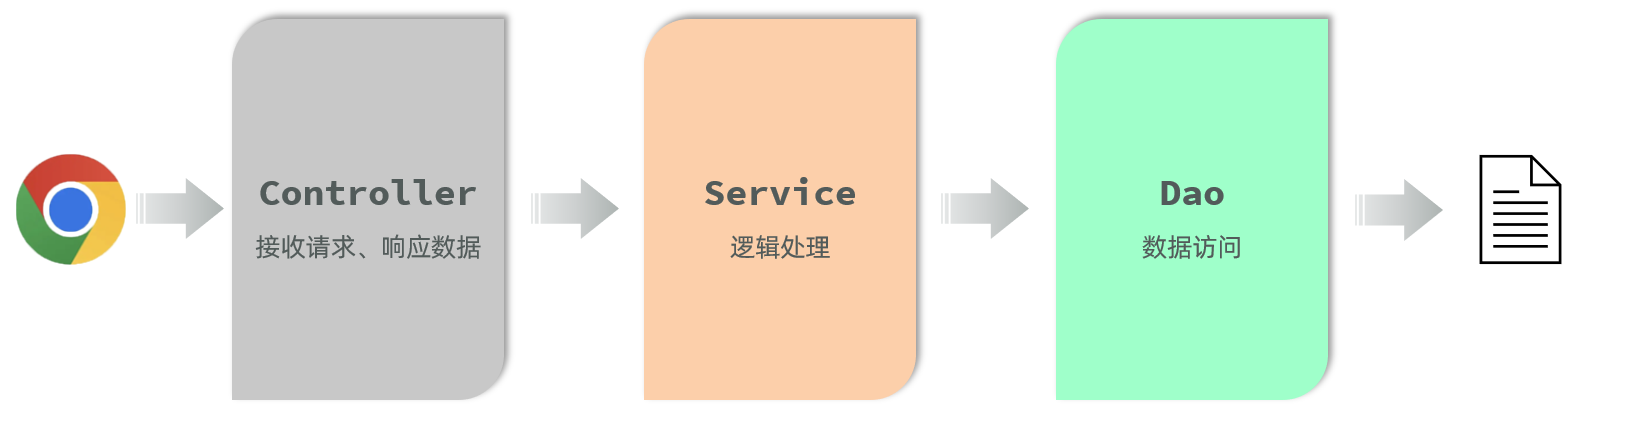

txt文件中可以存储数据，但是在企业项目开发中一般不会使用文本文件存储项目数据，因为不便管理维护，操作难度大。 

在真实的企业开发中呢，都会采用数据库来存储和管理数据，那此时，web开发调用流程图如下所示：

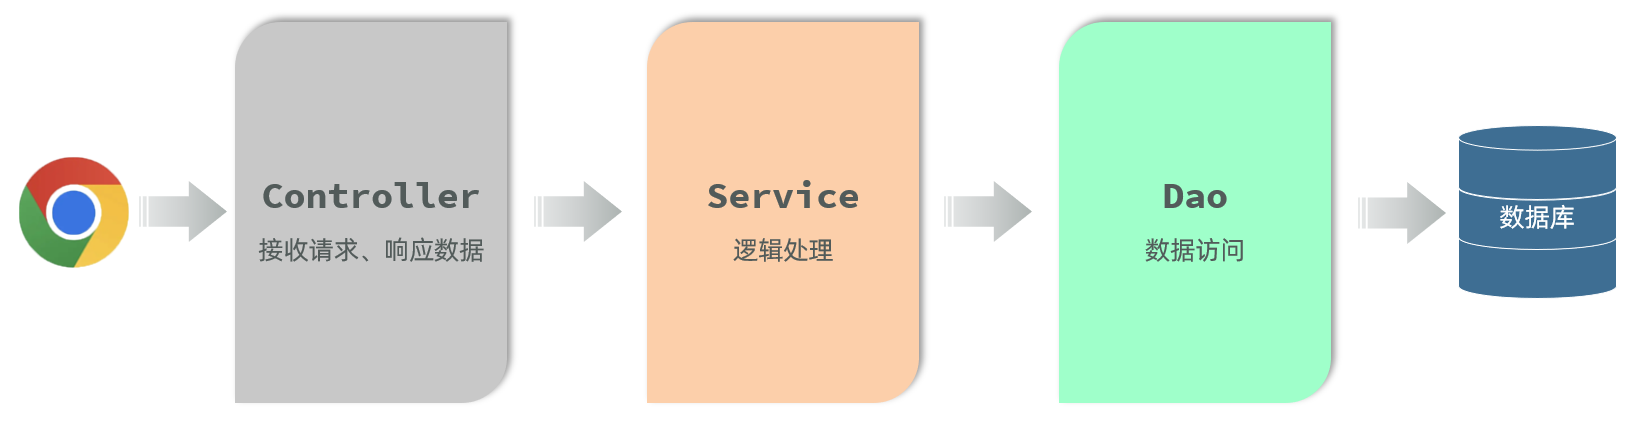

那么今天我们就要来学习数据库技术。


### 1.2 相关概念

**补充：先分清四个层次。**

| 名称 | 是什么 | 本章例子 |
| --- | --- | --- |
| DB | 存放表和数据的数据库 | `itcast`、`javaweb05_practice` |
| DBMS | 管理这些数据库的软件 | MySQL Server，服务端进程为 `mysqld` |
| SQL | 发给服务端的指令语言 | `SELECT name FROM emp;` |
| 客户端 | 连接服务端、发送 SQL、展示结果的工具 | `mysql` 命令行、DataGrip、IDEA 数据库工具 |

后文的数据库产品排名属于讲义当时的截图。“大型/中小型”只是粗略描述，不能据此判断产品能力；MySQL、PostgreSQL 都可以支持大规模业务。SQLite 的名称不是 SQLLite；它通常以内嵌库的方式工作。不同数据库共享不少 SQL 概念，但自增、分页、类型和函数等存在方言差异，切换产品仍需适配。

首先来了解一下什么是数据库。

- <strong>数据库：英文为 DataBase，简称DB，</strong><strong>它是存储和管理数据的仓库。</strong>

像我们日常访问的电商网站京东，企业内部的管理系统OA、ERP、CRM这类的系统，以及大家每天都会刷的头条、抖音类的app，那这些大家所看到的数据，其实都是存储在数据库中的。最终这些数据，只是在浏览器或app中展示出来而已，最终数据的存储和管理都是数据库负责的。

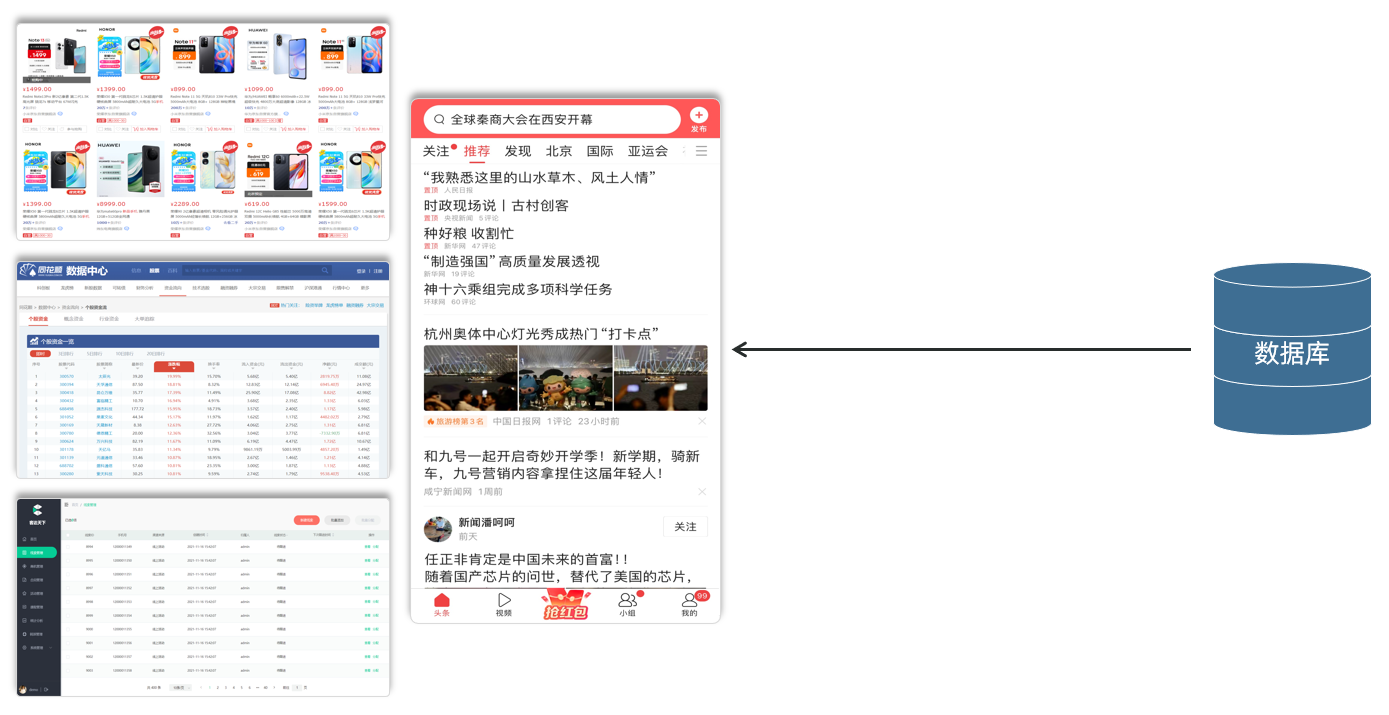

数据是存储在数据库中的，那我们要如何来操作数据库以及数据库中所存放的数据呢？

那这里呢，会涉及到一个软件，那就是数据库管理系统。

- <strong>数据库管理系统（DataBase Management System，简称DBMS），是操作和管理数据库的大型软件。</strong>

将来我们只需要操作这个软件，就可以通过这个软件来操纵和管理数据库了。

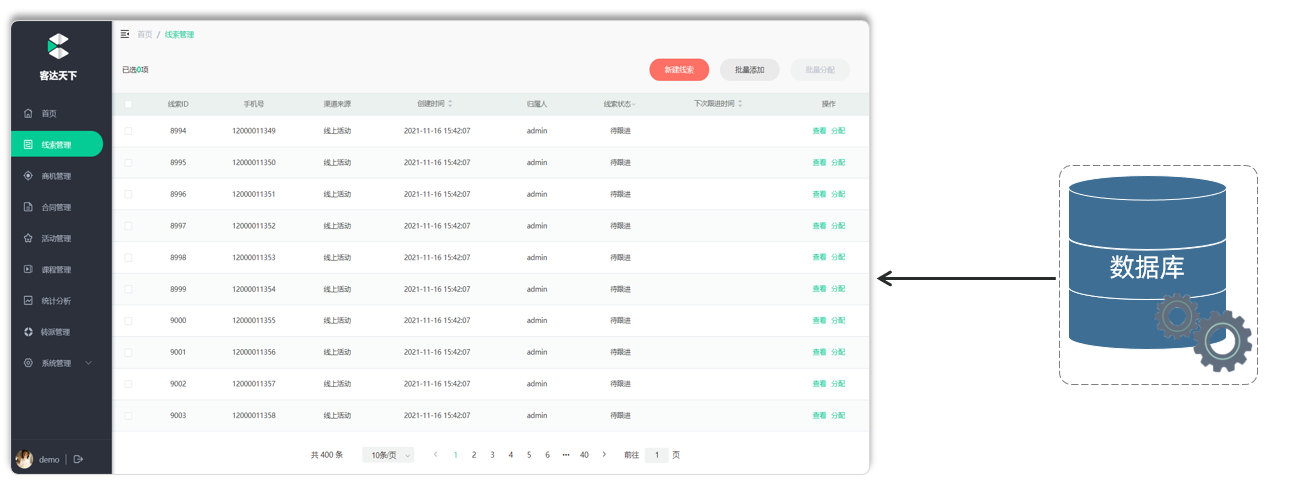

此时又出现一个问题：DBMS这个软件怎么知道要操作的是哪个数据库、哪个数据呢？是对数据做修改还是查询呢？

需要给DBMS软件发送一条指令，告诉这个软件我们要执行的是什么样的操作，要对哪个数据进行操作。而这个指令就是SQL语句。<br>

- <strong>SQL（Structured Query Language，简称SQL）：结构化查询语言，它是操作</strong><strong>关系型数据库的</strong><strong>编程语言，定义了一套操作关系型数据库的统一标准。</strong>

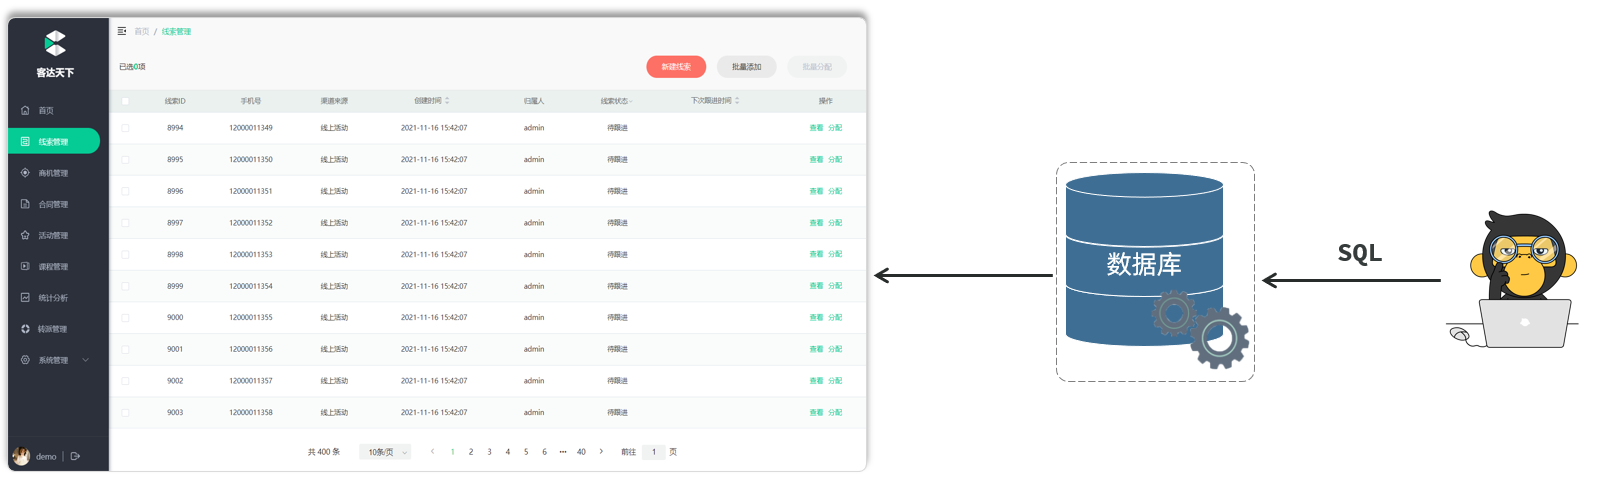

我们学习数据库开发，最为重要的就是学习SQL语句 。

> 关系型数据库：我们后面会详细讲解，现在大家只需要知道我们学习的数据库属于关系型数据库即可。

<strong>结论：</strong>程序员给数据库管理系统(DBMS)发送SQL语句，再由数据库管理系统操作数据库当中的数据。

了解了数据库的一些简单概念之后，接下来我们再来介绍下目前主流的数据库，这里截取了排名前十的数据库：

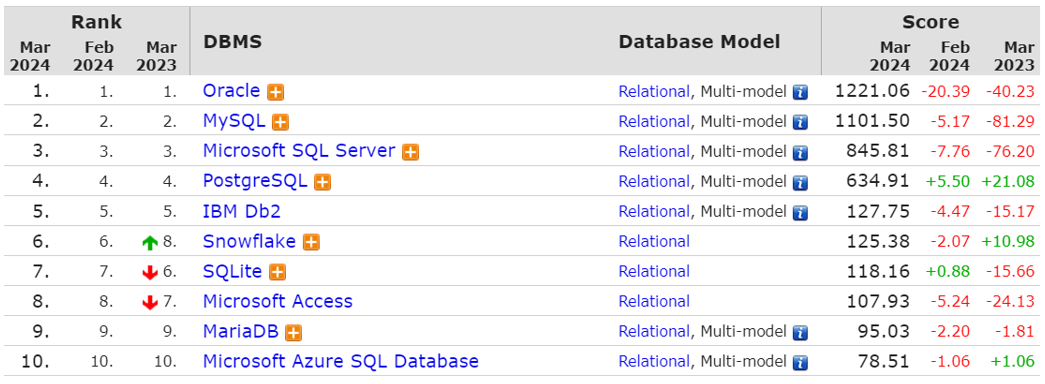

> - Oracle：大型的收费数据库，Oracle公司产品，价格昂贵。（通常是不差钱的公司会选择使用这个数据库）
> - MySQL：开源免费的中小型数据库，后来Sun公司收购了MySQL，而Oracle又收购了Sun公司。目前Oracle推出两个版本的Mysql：社区版(开源免费)、商业版(收费)。
> - SQL Server：Microsoft 公司推出的收费的中型数据库，C&#35;、.net等语言常用。
> - PostgreSQL：开源免费的中小型数据库。
> - DB2：IBM公司的大型收费数据库产品。
> - SQLLite：嵌入式的微型数据库。Android内置的数据库采用的就是该数据库。
> - MariaDB：开源免费的中小型数据库。是MySQL数据库的另外一个分支、另外一个衍生产品，与MySQL数据库有很好的兼容性。

那这么多数据库，我们全部都需要学习吗，其实并不用，我们只需要学习其中的一个就可以了，我们此次课程中学习的数据库是现在互联网公司开发使用最为流行的MySQL数据库。

此时大家可能会有一个疑问，我们现在学习的是Mysql数据库，我们以后去公司做开发，如果用到的是Oracle数据库或SQL Server数据库该怎么办？其实大家完全不用担心这个问题，因为这些数据库都是属于关系型数据库，要操作关系型数据库都是通过 SQL语句来实现的，而SQL语句又是操作关系型数据库的统一标准。

<strong>结论：</strong>只要我们学会了SQL语句，就可以通过SQL语句来操作Mysql，也可以通过SQL语句来操作Oracle或SQL Server

课程内容安排：

1. MySQL概述
2. SQL语句（DDL、DML、DQL）
3. 多表设计
4. 多表查询
5. 事务
6. 索引

那么今天呢，我们先来学习前两个章节（MySQL概述、SQL语句），后面随着课程的深入，我们再来讲解后面的课程内容。


## 2 MySQL概述

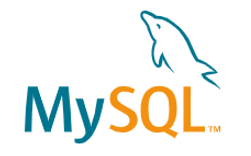

官网：https://dev.mysql.com/

<strong>MySQL官方提供了两个版本：</strong>

- 商业版本（MySQL Enterprise Edition）

    - 该版本是收费的，我们可以使用30天。 官方会提供对应的技术支持。
- 社区版本（MySQL Community Server）

    - 该版本是免费的，但是MySQL不会提供任何的技术支持。

> 本课程，采用的是MySQL的社区版本（8.0.34）


### 2.1 安装

> **补充：**本章采用课程版本 MySQL Community Server **8.0.34**；安装文档已并入第 4 节。安装服务端、启动服务、使用客户端连接，是三个不同步骤。MySQL 8.0.34 用于复现课程，不表示它是当前最新版本；已有兼容的 MySQL 8.x 环境可先检查版本，不必重复安装。

官网下载地址：<a href="https://downloads.mysql.com/archives/community/">https://downloads.mysql.com/archives/community/</a>

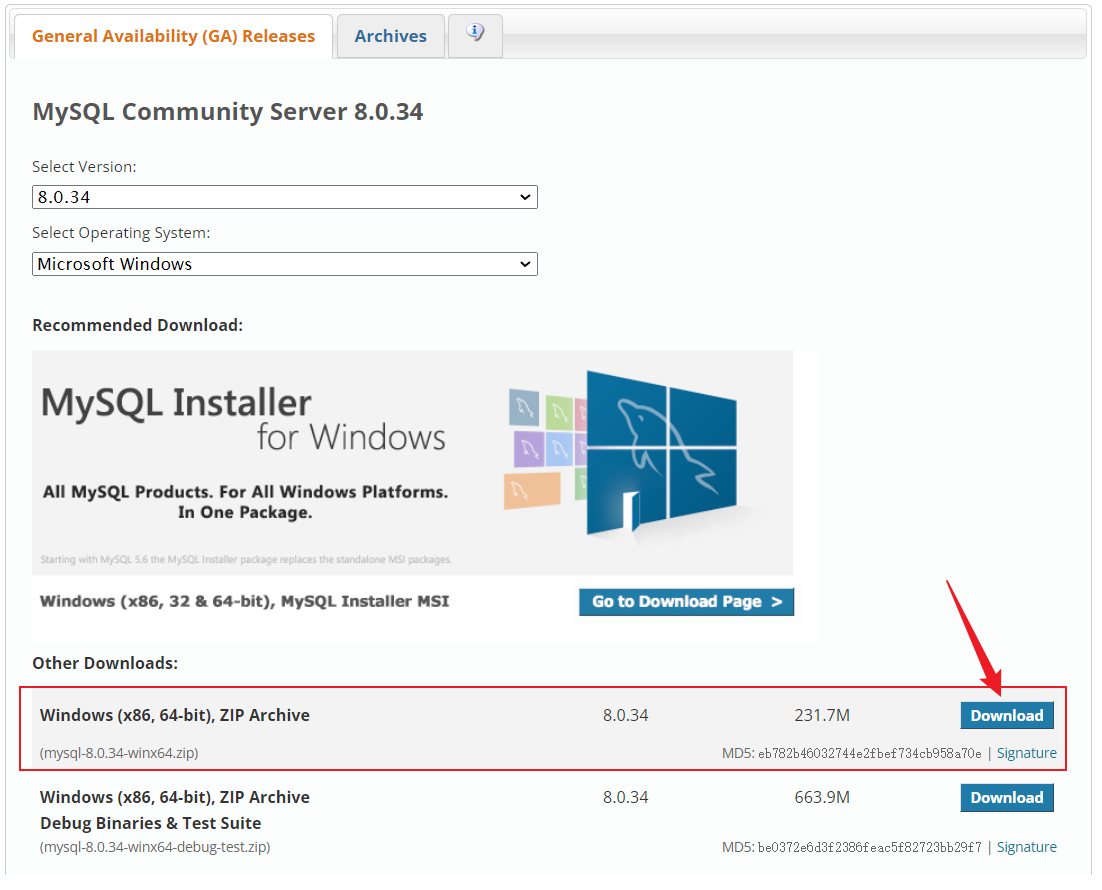

这个安装包呢，大家可以不用下载，因为资料中已提供现成的安装包。 

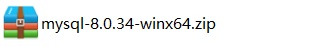

> 安装MySQL具体的步骤，参考<a href="https://heuqqdmbyk.feishu.cn/wiki/ZRSFwACsRiBD2NkV7bmcrJhInme">MySQL安装文档</a> ，进行软件的安装即可。


### 2.2 连接


#### 2.2.1 介绍

MySQL服务器启动完毕后，然后再使用如下指令，来连接MySQL服务器：

````text
mysql -u用户名 -p密码 [-h数据库服务器的IP地址 -P端口号]
````

> **补充：**这是终端命令，不是 Java 或 SQL。`-u` 是用户名，`-p` 表示输入密码，`-h` 是主机，**大写** `-P` 是端口。省略主机通常使用 localhost，具体连接方式受系统及配置影响；希望明确走本机 TCP 时写 `127.0.0.1`。

```text
mysql -h 127.0.0.1 -P 3306 -u root -p
```

回车后在密码提示处输入密码；输入不回显是正常现象。出现 `mysql>` 后才输入 SQL：

```sql
SELECT VERSION(), DATABASE();
```

尚未选择数据库时，`DATABASE()` 返回 NULL，并不表示连接失败。

- -h  参数不加，默认连接的是本地 127.0.0.1 的MySQL服务器
- -P  参数不加，默认连接的端口号是 3306

<strong>上述指令，可以有两种形式：</strong>

- 密码直接在-p参数之后直接指定 （这种方式不安全，密码直接以明文形式出现在命令行）

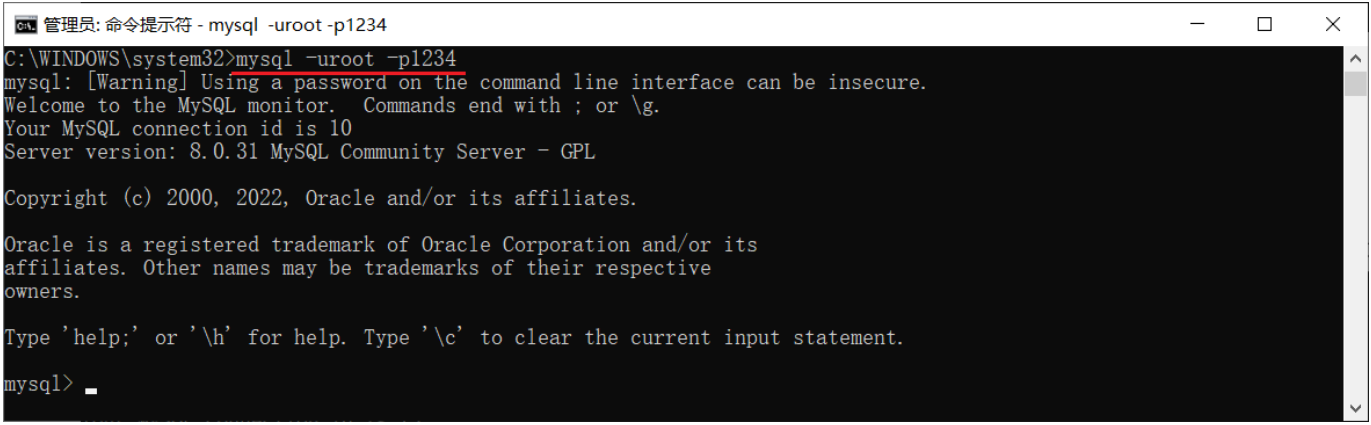

- 密码在-p回车之后，在命令行中输入密码，然后回车

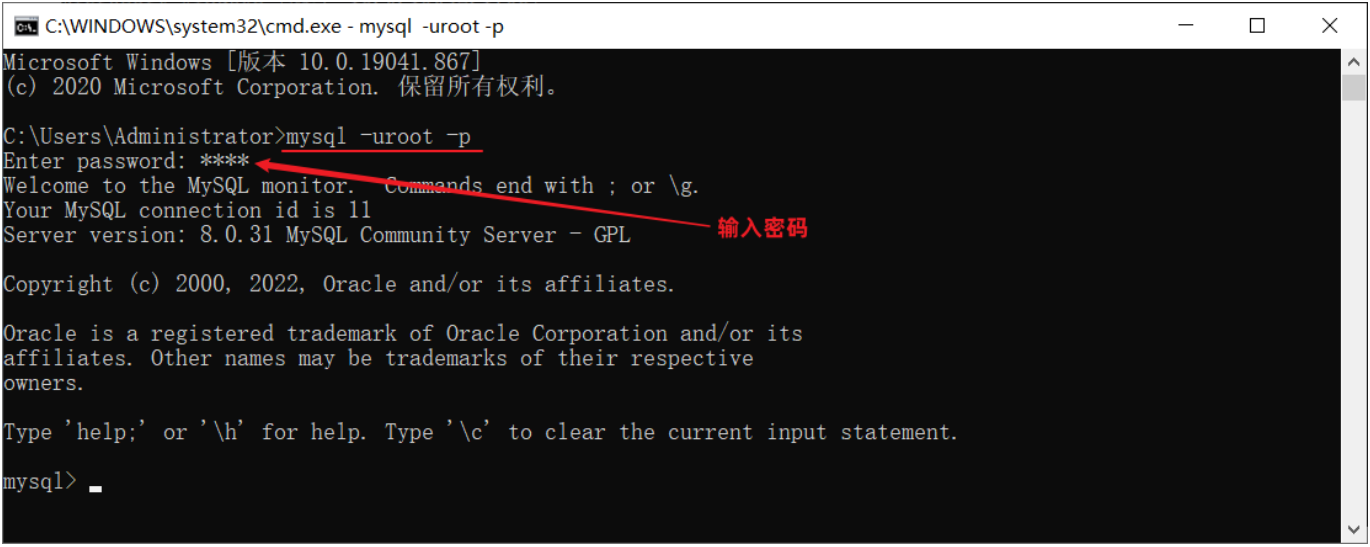


#### 2.2.2 企业使用方式(了解)

> **补充：**这是集中部署的常见模式。企业也会使用云数据库、本地开发库或容器测试库，并非所有数据库都必须自建 IDC。浏览器一般调用后端接口，再由后端访问数据库；不要把数据库连接账号直接放进前端代码。

上述的MySQL服务器我们是安装在本地的，这个仅仅是在我们学习阶段，在真实的企业开发中，MySQL数据库服务器是不会在我们本地安装的，是在公司的服务器上安装的，而服务器还需要放置在专门的IDC机房中的，IDC机房呢，就需要保证恒温、恒湿、恒压，而且还要保证网络、电源的可靠性(备用电源及网络)。

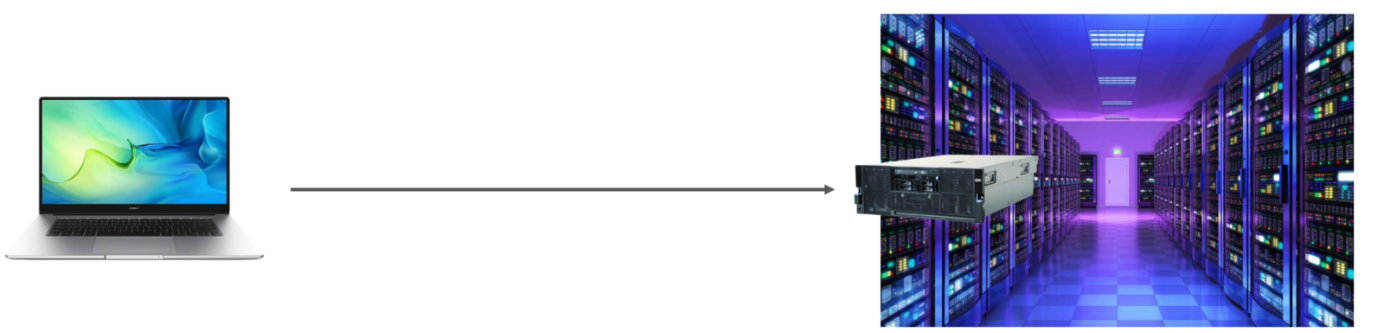

那我们要想使用服务器上的这台MySQL服务器，就需要在我们的电脑上去远程连接这台MySQL 。 而服务器上安装的MySQL数据库呢，并不是你一个人在访问，我们项目组的其他开发人员也是需要访问这台MySQL的。

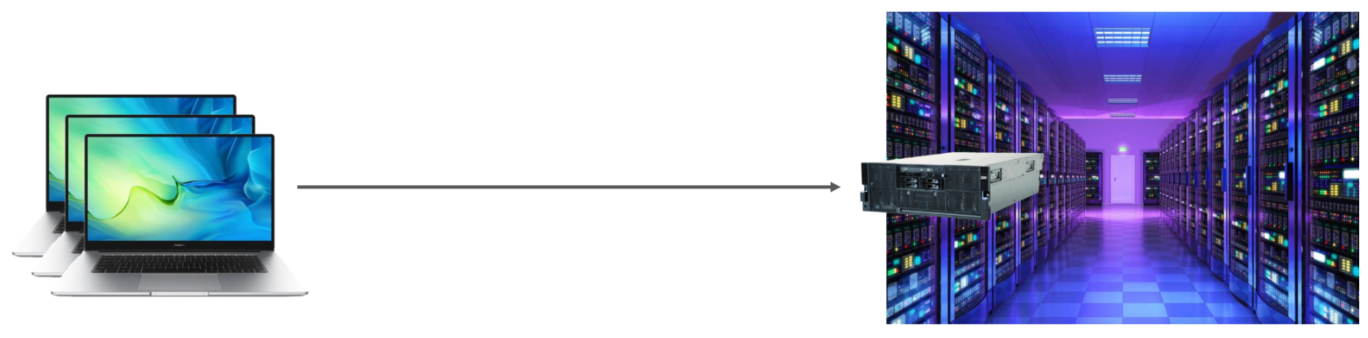

接下来，就来演示一下，通过MySQL的客户端命令行，如何来连接服务器上部署的MySQL ： 

````text
mysql [-h数据库服务器的IP地址 -P端口号] -u用户名 -p密码
````

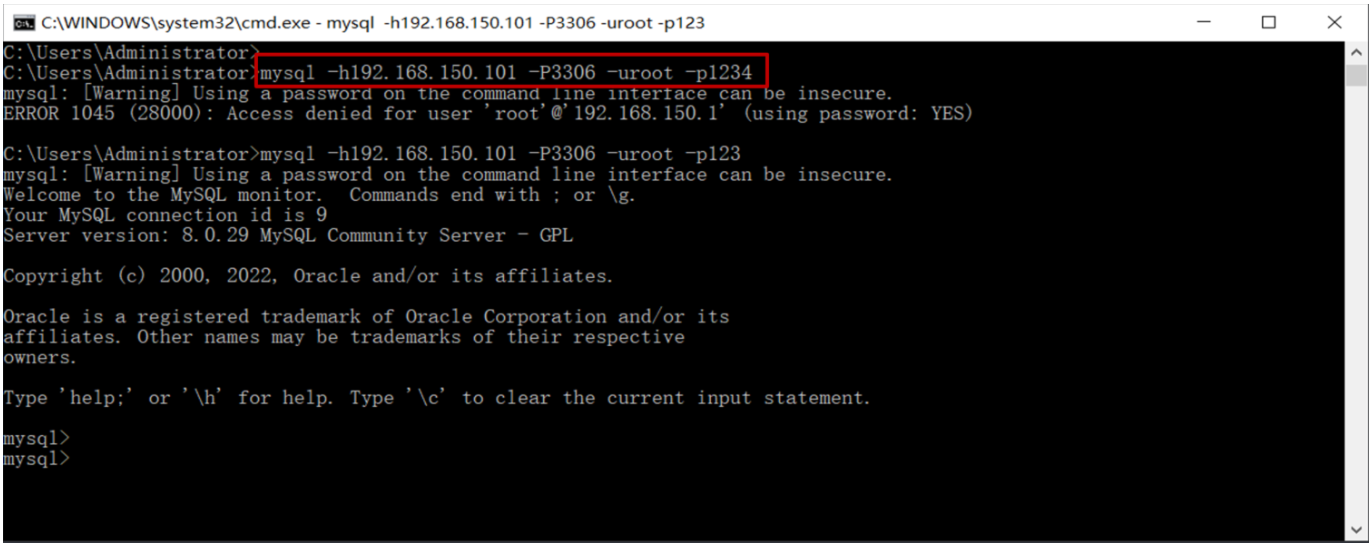


### 2.3 数据模型

介绍完了Mysql数据库的安装配置之后，接下来我们再来聊一聊Mysql当中的数据模型。学完了这一小节之后，我们就能够知道在Mysql数据库当中到底是如何来存储和管理数据的。

在介绍 Mysql的数据模型之前，需要先了解一个概念：关系型数据库。


#### 2.3.1 关系型数据库（RDBMS）

概念：建立在关系模型基础上，由多张相互连接的<strong>二维表</strong>组成的数据库。而所谓二维表，指的是由行和列组成的表，如下图：

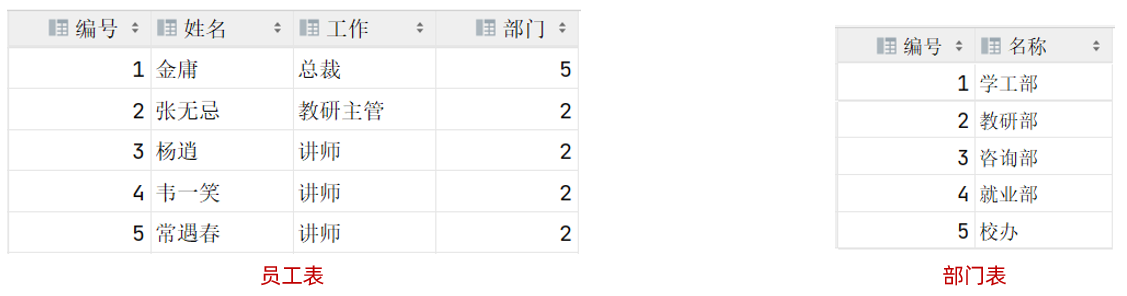

二维表的优点：

- 使用表存储数据，格式统一，便于维护
- 使用SQL语言操作，标准统一，使用方便，可用于复杂查询

> 我们之前提到的MySQL、Oracle、DB2、SQLServer这些都是属于关系型数据库，里面都是基于二维表存储数据的。
> 
> <strong>结论：</strong>基于二维表存储数据的数据库就成为关系型数据库，不是基于二维表存储数据的数据库，就是非关系型数据库（比如大家后面要学习的Redis，就属于非关系型数据库）。


#### 2.3.2 数据模型

**补充：把存储层次写成目录树。**

```text
一个 MySQL 服务实例（主机 + 端口）
└── 数据库 javaweb05_practice
    ├── 表 emp
    │   ├── 列：id、username、name、salary……
    │   └── 行：一名员工是一条记录
    └── 表 tb_user
```

关系型数据库以关系模型为基础，不能只凭某个工具“能否显示成表格”来分类。表内记录也没有业务上保证的默认顺序，需要排序时显式写 `ORDER BY`。

介绍完了关系型数据库之后，接下来我们再来看一看在Mysql数据库当中到底是如何来存储数据的，也就是Mysql 的数据模型。

MySQL是关系型数据库，是基于二维表进行数据存储的，具体的结构图下:

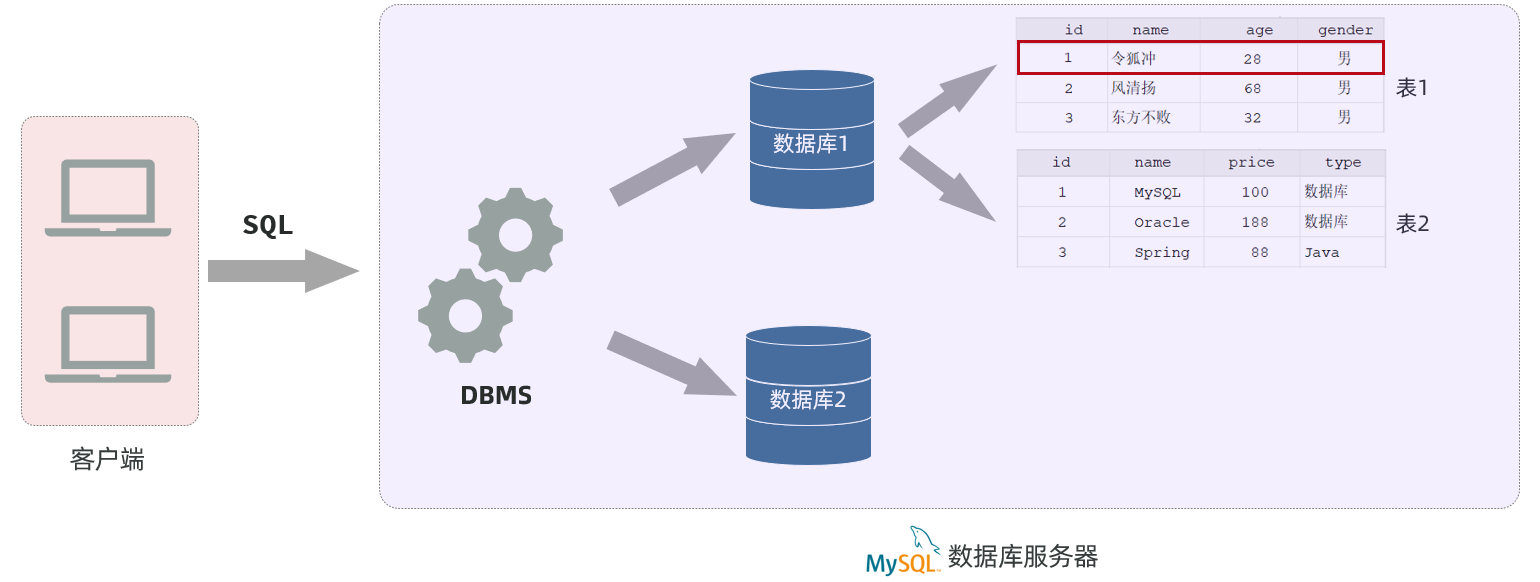

- 通过MySQL客户端连接数据库管理系统DBMS，然后通过DBMS操作数据库。
- 使用MySQL客户端，向数据库管理系统发送一条SQL语句，由数据库管理系统根据SQL语句指令去操作数据库中的表结构及数据。
- 一个数据库服务器中可以创建多个数据库，一个数据库中也可以包含多张表，而一张表中又可以包含多行记录。

> 在Mysql数据库服务器当中存储数据，你需要：
> 
> 1. 先去创建数据库（可以创建多个数据库，之间是相互独立的）
> 2. 在数据库下再去创建数据表（一个数据库下可以创建多张表）
> 3. 再将数据存放在数据表中（一张表可以存储多行数据）


## 3 SQL语句

**补充：SQL 的阅读与执行约定。**本节在 MySQL 客户端或 DataGrip 查询控制台运行，不能把 SQL 当作 Notebook 的 Python 代码执行。

- 一条语句可跨多行，通常用分号 `;` 结束。`[ ]` 表示语法说明中的可选部分，不要把方括号和“表名”等中文占位词原样执行。
- 关键字通常不区分大小写；数据库名、表名的大小写行为与操作系统和 `lower_case_table_names` 有关，统一小写可减少跨环境问题。
- 字符串和日期推荐单引号 `'...'`，标识符有特殊字符时用反引号；双引号的含义可能受 `ANSI_QUOTES` 模式影响。
- 注释可写 `-- 注释`（双横线后有空白）、`/* 注释 */`；`# 注释` 是 MySQL 支持的写法。
- 本章保留逐步演示的建表、删表、改名片段，它们不是一份应从头一口气执行到底的脚本。完整跟练顺序见第 6 节。

SQL：结构化查询语言。一门操作关系型数据库的编程语言，定义操作所有关系型数据库的统一标准。SQL语句根据其功能被分为四大类：DDL、DML、DQL、DCL 。

| 分类 | 全称 | 说明 |
| --- | --- | --- |
| DDL | Data Definition Language | 数据定义语言，用来定义数据库对象(数据库，表，字段) |
| DML | Data Manipulation Language | 数据操作语言，用来对数据库表中的数据进行增删改 |
| DQL | Data Query Language | 数据查询语言，用来查询数据库中表的记录 |
| DCL | Data Control Language | 数据控制语言，用来创建数据库用户、控制数据库的访问权限 |

> **补充：**这是课程的功能分类；有些资料把 SELECT 归入广义 DML。分类名称不影响语句作用。本章重点是 DDL、DML、DQL，DCL 留到权限管理时再用。

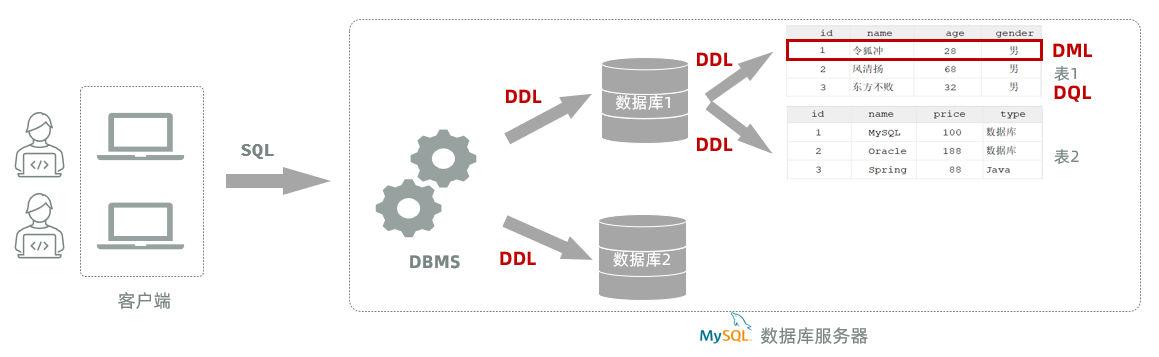


### 3.1 DDL语句


#### 3.1.1 数据库操作

我们在进行数据库设计，需要使用到刚才所介绍SQL分类中的DDL语句。

DDL英文全称是Data Definition Language(数据定义语言)，用来定义数据库对象(数据库、表)。

DDL中数据库的常见操作：查询、创建、使用、删除。


##### 3.1.1.1 查询数据库

- 查询所有数据库

````sql
show databases;
````

命令行中执行效果如下：

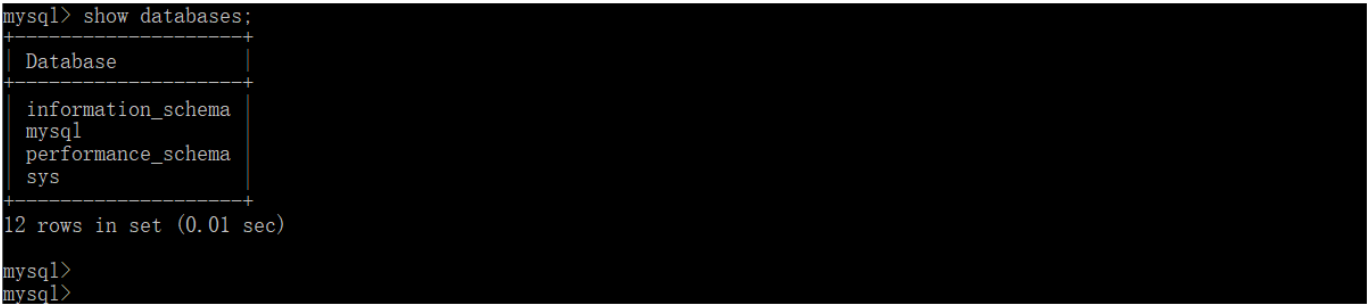

- 查询当前数据库

````sql
select database();
````

命令行中执行效果如果：

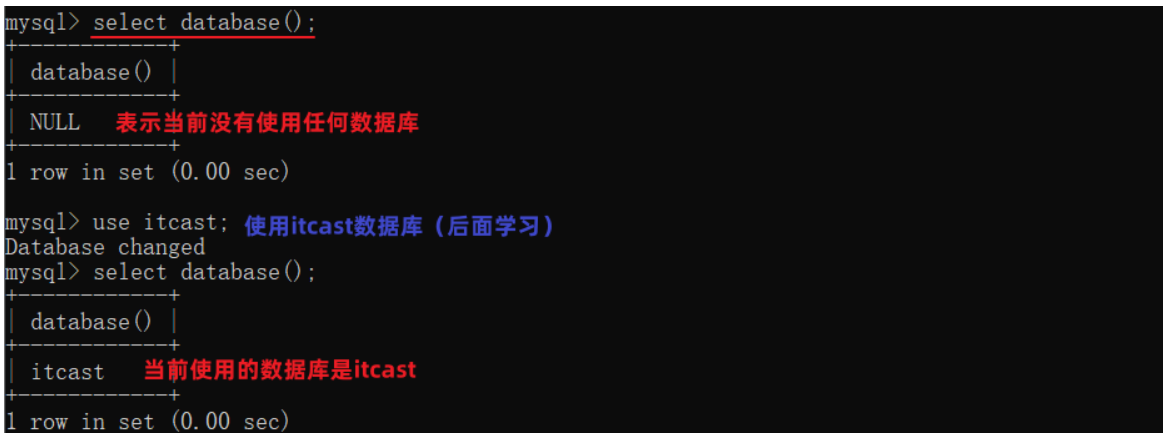

> 我们要操作某一个数据库，必须要切换到对应的数据库中。 
> 
> 通过指令：select  database() ，就可以查询到当前所处的数据库


##### 3.1.1.2 创建数据库

- 语法：

````sql
create database [ if not exists ] 数据库名  [default charset utf8mb4];
````

> **补充：**MySQL 8.0 的默认字符集通常是 `utf8mb4`，但服务端设置可能被修改。明确写 `CHARACTER SET utf8mb4` 更容易复现；它支持包括常见 emoji 在内的四字节字符。字符集决定能存哪些字符，排序规则（collation）决定文本如何比较和排序，例如是否区分大小写。

创建数据库时，可以不指定字符集。 因为在MySQL8版本之后，默认的字符集就是 utf8mb4。

- 案例： 创建一个itcast数据库。

````sql
create database itcast;
````

命令行执行效果如下：

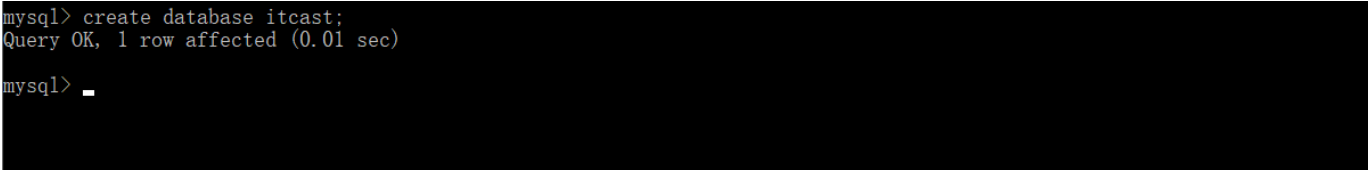

注意：在同一个数据库服务器中，不能创建两个名称相同的数据库，否则将会报错。

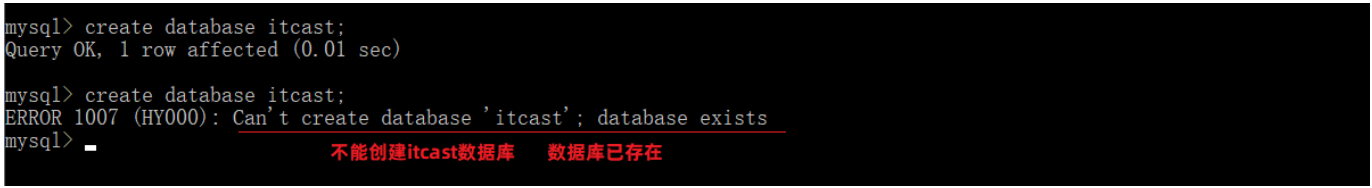

可以使用<code>if not exists</code>来避免这个问题

````sql
-- 数据库不存在,则创建该数据库；如果存在则不创建
create database if not exists itcast; 
````

命令行执行效果如下： 

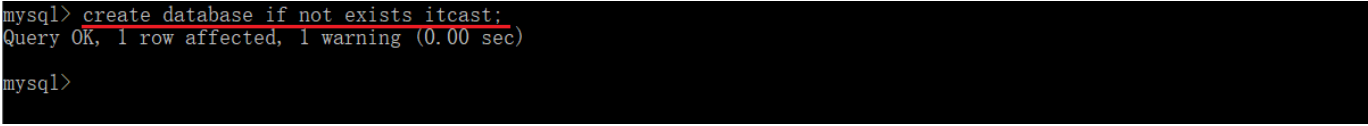


##### 3.1.1.3 使用数据库

- 语法：

````sql
use 数据库名 ;
````

我们要操作某一个数据库下的表时，就需要通过该指令，切换到对应的数据库下，否则不能操作。

- 案例：切换到itcast数据

````sql
use itcast;
````

> **勘误：**`USE` 用于设置当前连接的默认数据库，不是操作表的唯一方式；也可以写 `SELECT * FROM itcast.tb_user;` 明确数据库名。不同连接/控制台可能选择不同的默认库，执行前可用 `SELECT DATABASE();` 确认。

命令执行效果如下：

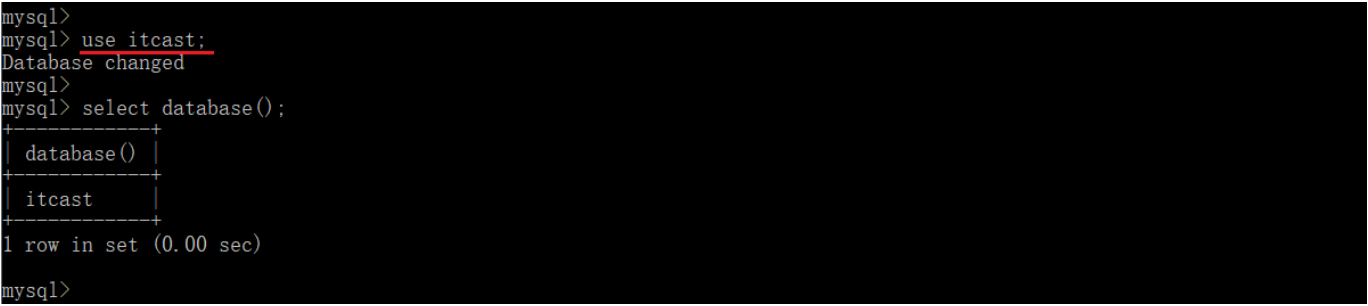


##### 3.1.1.4 删除数据库

- 语法:

    ````sql
    drop database [ if exists ] 数据库名 ;
    ````

    - 如果删除一个不存在的数据库，将会报错。
    - 可以加上参数 if exists ，如果数据库存在，再执行删除，否则不执行删除。

- 案例：删除itcast数据库

    ````sql
    drop database if exists itcast; -- itcast数据库存在时删除
    ````

    > **跟练说明：**这条语句会连同库内表和数据一起删除 `itcast`。`IF EXISTS` 仅避免“不存在”的报错，不提供数据保护。删除库演示结束后，后续建表前应重新建库并 `USE`，或改用单独的练习库。

    命令执行效果如下：

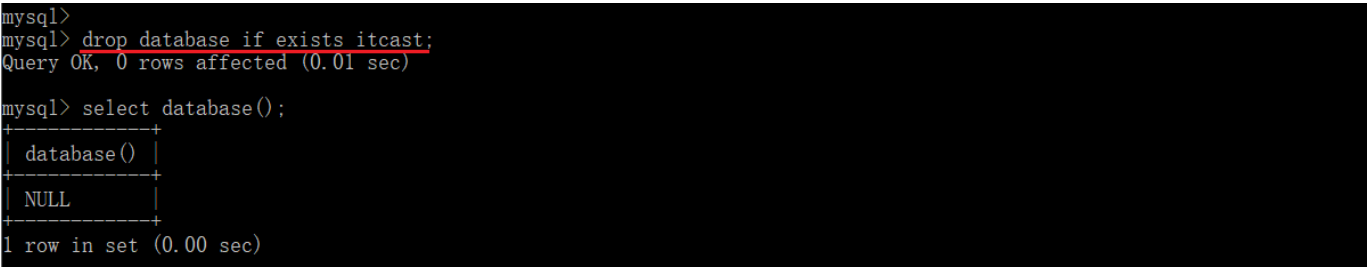

> <strong>说明：</strong><strong>上述语法中的database，也可以替换成 schema</strong>
> 
> - 如：create schema db01;
> - 如：show schemas;


#### 3.1.2 图形化工具


##### 3.1.2.1 介绍

> **勘误：**“命令行编写的 SQL 无法保存”不准确：可以保存为 `.sql` 文件，再由客户端执行。图形工具的优势主要是代码提示、结果展示和对象浏览；背后仍然是发送 SQL。

前面我们讲解了DDL中关于数据库操作的SQL语句，在我们编写这些SQL时，都是在命令行当中完成的。大家在练习的时候应该也感受到了，在命令行当中来敲这些SQL语句很不方便，主要的原因有以下 3 点：

1. 没有任何代码提示。（全靠记忆，容易敲错字母造成执行报错）
2. 操作繁琐，影响开发效率。（所有的功能操作都是通过SQL语句来完成的）
3. 编写过的SQL代码无法保存。

在项目开发当中，通常为了提高开发效率，都会借助于现成的图形化管理工具来操作数据库。

目前MySQL主流的图形化界面工具有以下几种：

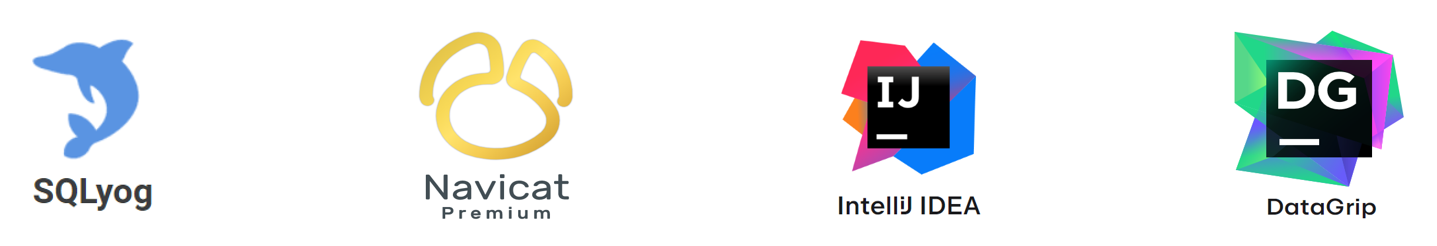

DataGrip是JetBrains旗下的一款数据库管理工具，是管理和开发MySQL、Oracle、PostgreSQL的理想解决方案。

官网： https://www.jetbrains.com/zh-cn/datagrip/


##### 3.1.2.2 安装

> **补充：**第 5 节并入 DataGrip 的安装、连接步骤。IDEA 的数据库工具能力取决于版本、插件和授权，不能把截图中的完整功能视为所有版本都自带。DataGrip 是客户端，安装它不会自动安装 MySQL Server。

安装： 参考资料中提供的《DataGrip安装手册》

> 说明：DataGrip这款工具可以不用安装，因为Jetbrains公司已经将DataGrip这款工具的功能已经集成到了 IDEA当中，所以我们就可以使用IDEA来作为一款图形化界面工具来操作Mysql数据库。


##### 3.1.2.3 连接数据库

**配图操作转写：**新建 Data Source → MySQL，填写 Host=`127.0.0.1`、Port=`3306`、User 和自己设置的密码，下载缺失的 JDBC 驱动后点击 **Test Connection**。JDBC 驱动是让这个 Java 客户端与 MySQL 通信的库；它不等于数据库服务端。连接成功后，在 Schemas 中勾选要显示的库，并为该库打开 Query Console。

如果 SQL 编辑器提示没有选择数据库，可在同一控制台执行 `USE 库名;`；只在左侧树形栏点击一个库，不一定改变另一条连接的默认库。

1). 创建Project

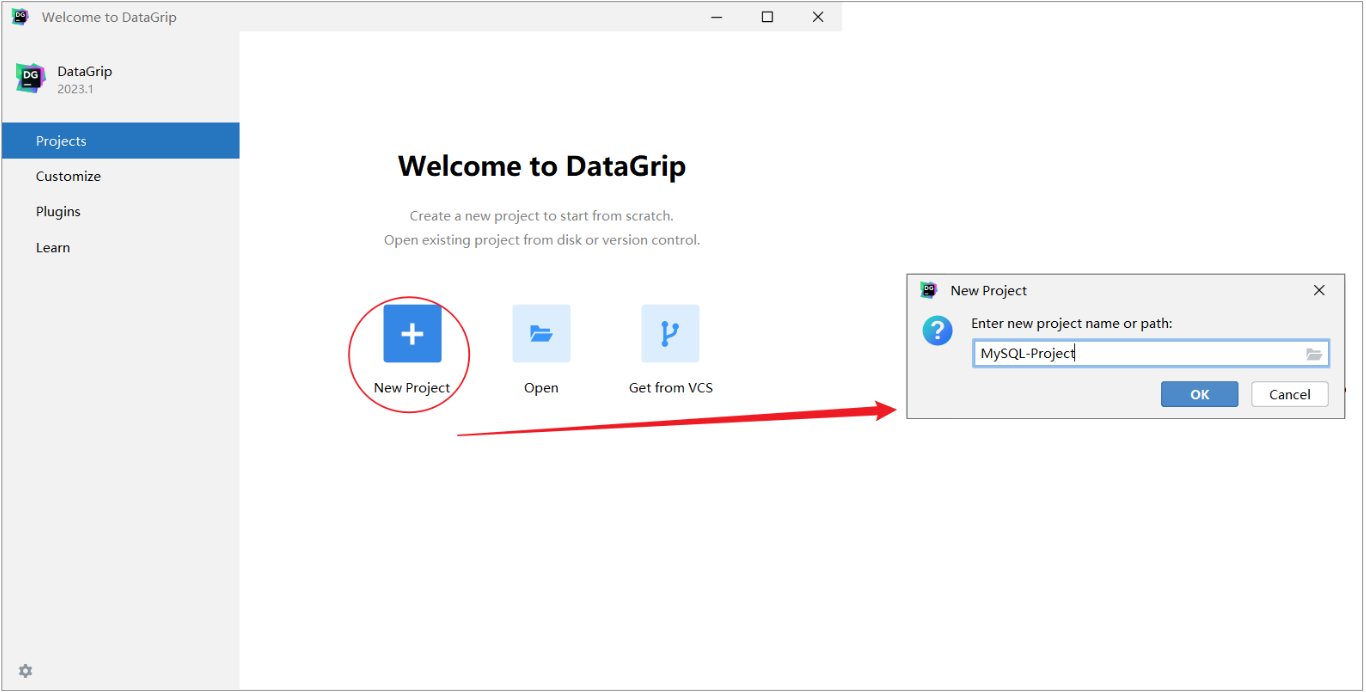

2). 创建连接

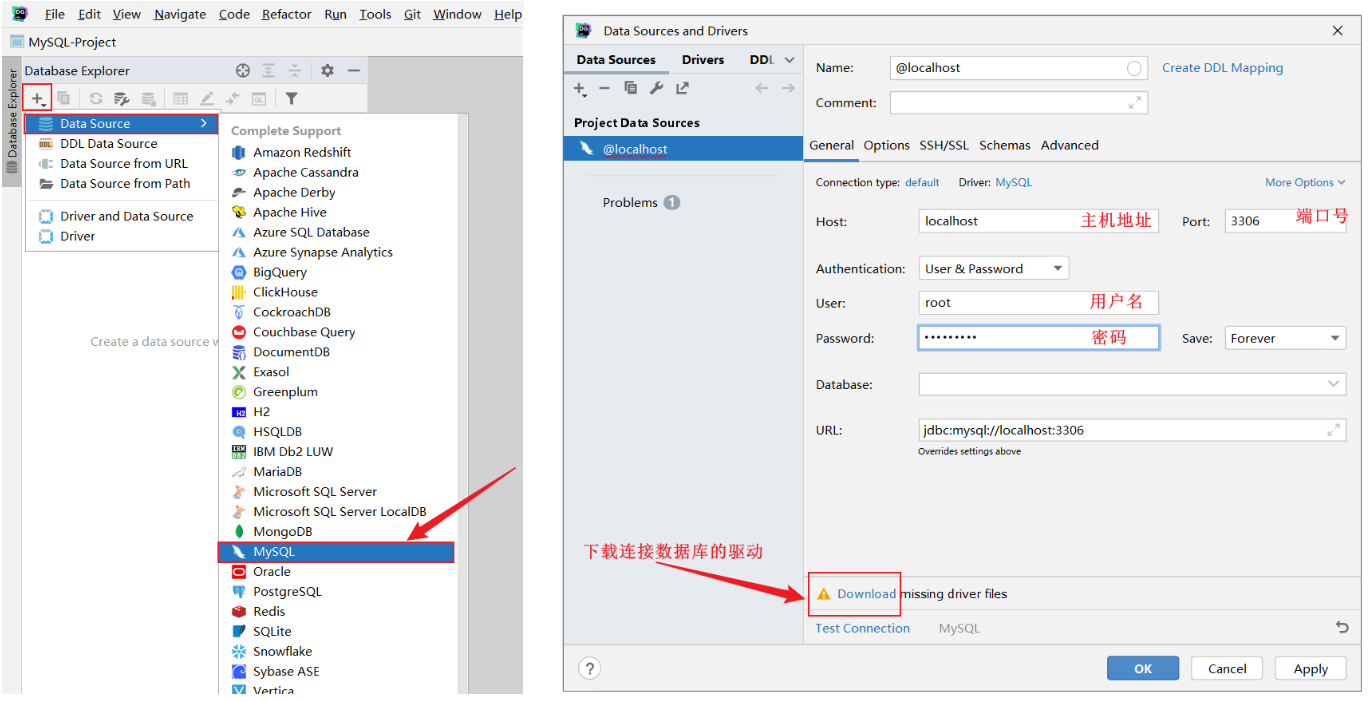

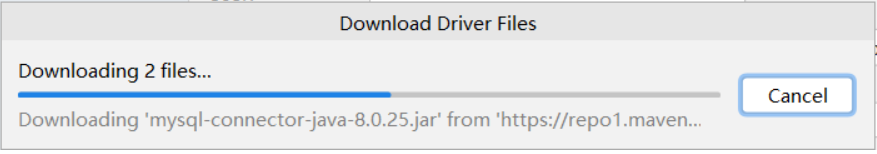

下载驱动, 可能会比较耗时, 耐心等待一会儿。 

3). 测试连接

下载完驱动之后，可以点击 <code>Test Connection</code> 来测试一下是否可以正常的连接数据库。

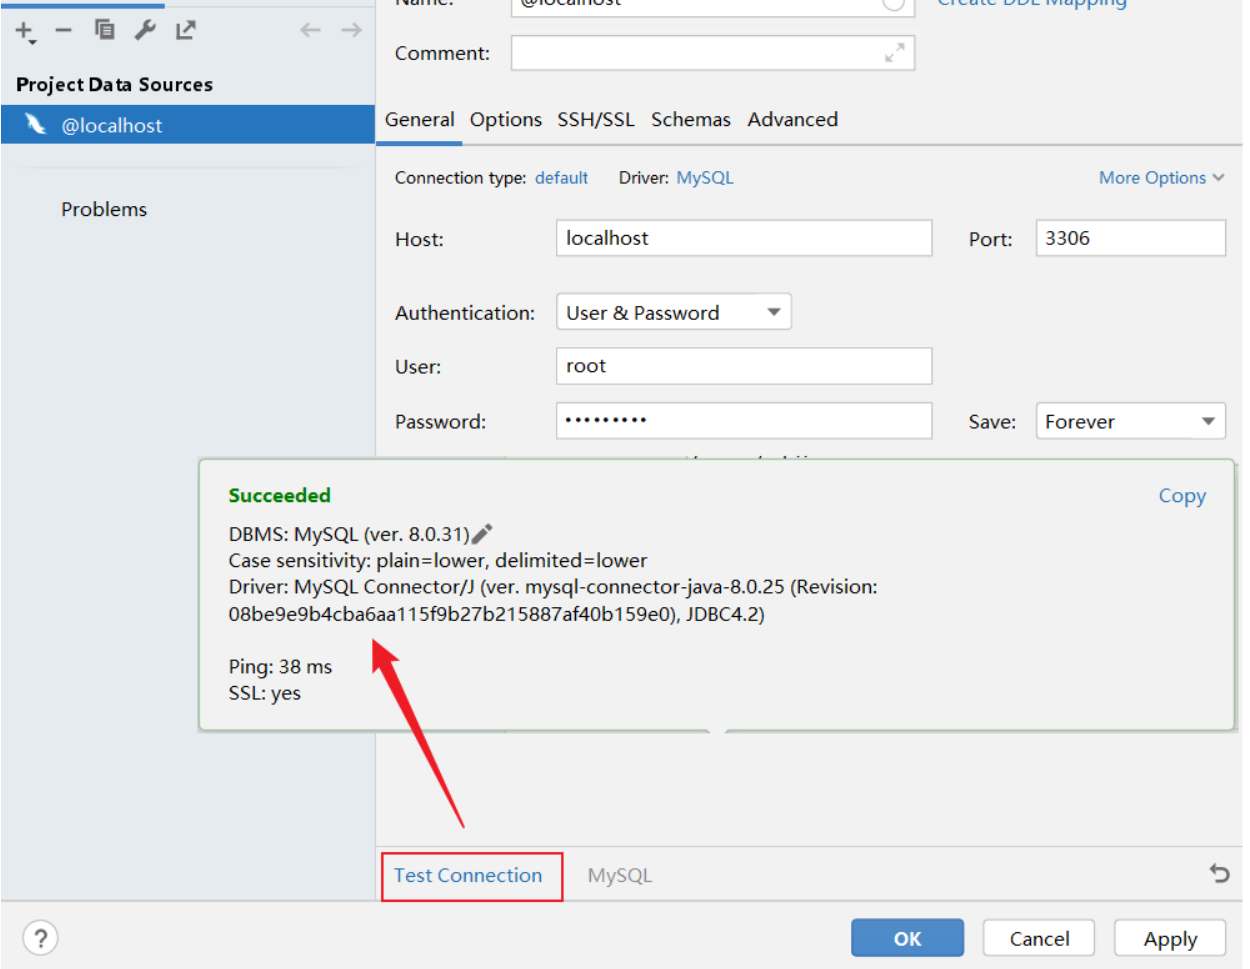

然后点击 OK ， 就已经连接上了MySQL数据库了。 

默认情况下，连接上了MySQL数据库之后， 数据库并没有全部展示出来。 需要选择要展示哪些数据库。具体操作如下：

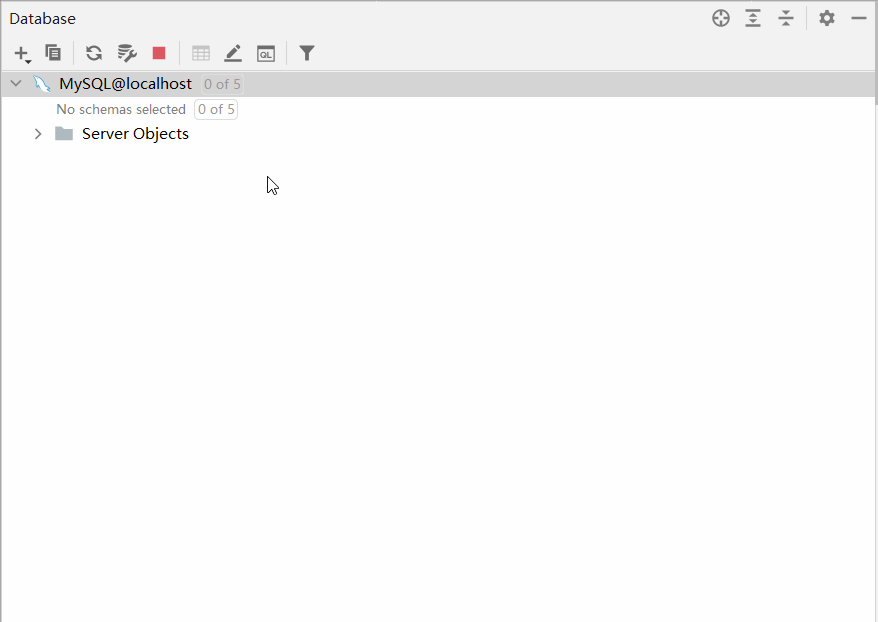


#### 3.1.3 表操作

学习完了DDL语句当中关于数据库的操作之后，接下来我们继续学习DDL语句当中关于表结构的操作。

关于表结构的操作也是包含四个部分：创建表、查询表、修改表、删除表。


##### 3.1.3.1 创建

- 语法：

    ````sql
    create table  表名(
            字段1  字段1类型 [约束]  [comment  字段1注释 ],
            字段2  字段2类型 [约束]  [comment  字段2注释 ],
            ......
            字段n  字段n类型 [约束]  [comment  字段n注释 ] 
    ) [ comment  表注释 ] ;
    ````

    - 注意： &#91; &#93; 中的内容为可选参数； 最后一个字段后面没有逗号

- 案例：创建tb&#95;user表

    - 对应的结构如下：

    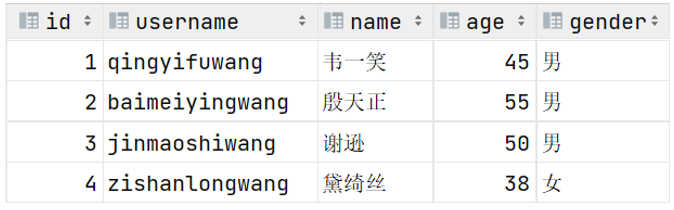

    - 建表语句：

    ````sql
    create table tb_user (
        id int comment 'ID,唯一标识',   # id是一行数据的唯一标识（不能重复）
        username varchar(20) comment '用户名',
        name varchar(10) comment '姓名',
        age int comment '年龄',
        gender char(1) comment '性别'
    ) comment '用户表';
    ````

    > **补充：**`COMMENT 'ID,唯一标识'` 只是说明文字，数据库不会因此检查唯一性。下一小节用真正的 `PRIMARY KEY` 实现约束。下面连续出现的三版 `CREATE TABLE tb_user` 是同一张表的迭代版本，不能在同一个库里重复创建同名表；用空的练习表分别体验，或直接采用最后一版。

    - 数据表创建完成，接下来我们还需要测试一下是否可以往这张表结构当中来存储数据。

    双击打开tb&#95;user表结构，大家会发现里面没有数据：

    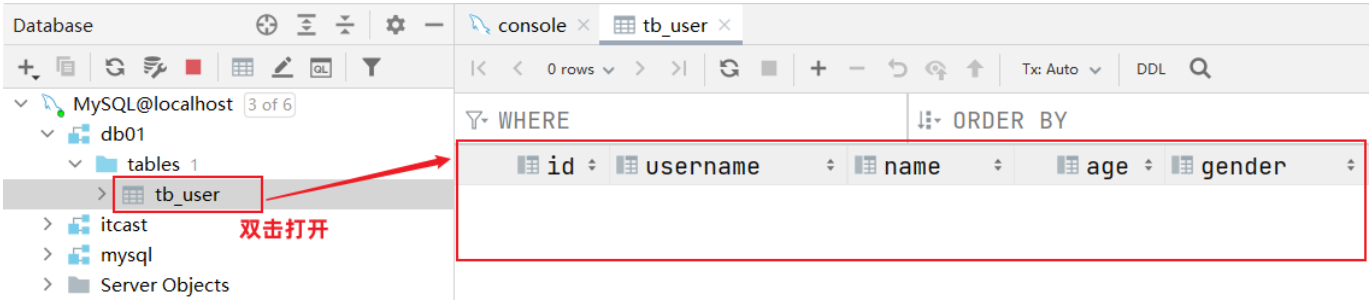

添加数据：

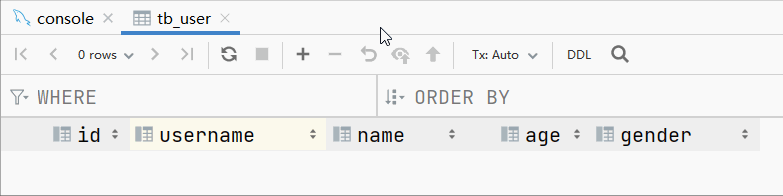

    此时我们再插入一条数据：

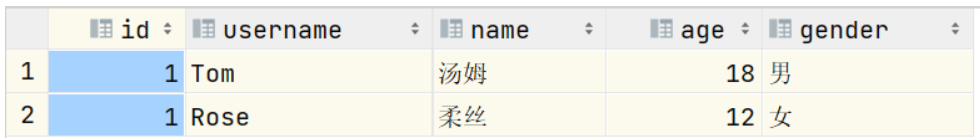

我们之前提到过：id字段是一行数据的唯一标识，不能有重复值。但是现在数据表中有两个相同的id值，这是为什么呢？

- 其实我们现在创建表结构的时候， id这个字段我们只加了一个备注信息说明它是一个唯一标识，但是在数据库层面呢，并没有去限制字段存储的数据。所以id这个字段没有起到唯一标识的作用。

> 想要限制字段所存储的数据，就需要用到数据库中的约束。


##### 3.1.3.2 约束

- 概念：所谓约束就是作用在表中字段上的规则，用于限制存储在表中的数据。
- 作用：就是来保证数据库当中数据的正确性、有效性和完整性。（后面的学习会验证这些）
- 在MySQL数据库当中，提供了以下5种约束：

| 约束 | 描述 | 关键字 |
| --- | --- | --- |
| 非空约束 | 限制该字段值不能为null | not null |
| 唯一约束 | 保证字段的所有数据都是唯一、不重复的 | unique |
| 主键约束 | 主键是一行数据的唯一标识，要求非空且唯一 | primary key |
| 默认约束 | 保存数据时，如果未指定该字段值，则采用默认值 | default |
| 外键约束 | 让两张表的数据建立连接，保证数据的一致性和完整性 | foreign key |

> **补充与勘误：**表中列的是本节介绍的 5 类规则，不是 MySQL 所有约束的完整清单，例如还支持 CHECK。`NOT NULL` 不等于“不允许空字符串”；可空列的 UNIQUE 通常允许多个 NULL；一张表只有一个主键约束，但可由多列组合。DEFAULT 只在省略该列或使用 DEFAULT 时提供默认值，显式传 NULL 不会普遍被替换成默认值。外键的细节在后续多表设计中展开。

> 注意：约束是作用于表中字段上的，可以在创建表/修改表的时候添加约束。

- 案例：创建tb&#95;user表，对应的结构如下：

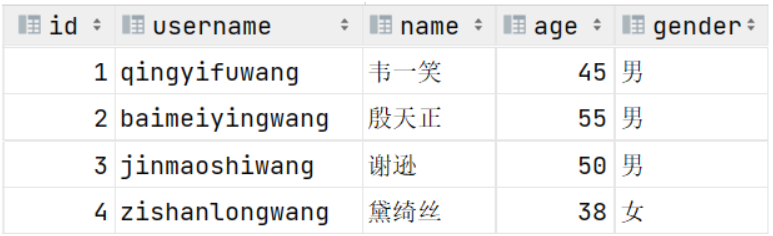

在上述的表结构中:

- id 是一行数据的 <strong>唯一标识</strong>
- username 用户名字段是<strong>非空</strong>且<strong>唯一</strong>的
- name 姓名字段是<strong>不允许存储空值</strong>的
- gender 性别字段是有<strong>默认值</strong>，默认为男

建表语句：

````sql
create table tb_user (
    id int primary key comment 'ID,唯一标识', 
    username varchar(20) not null unique comment '用户名',
    name varchar(10) not null comment '姓名',
    age int comment '年龄',
    gender char(1) default '男' comment '性别'
) comment '用户表';
````

数据表创建完成，接下来测试一下表中字段上的约束是否生效

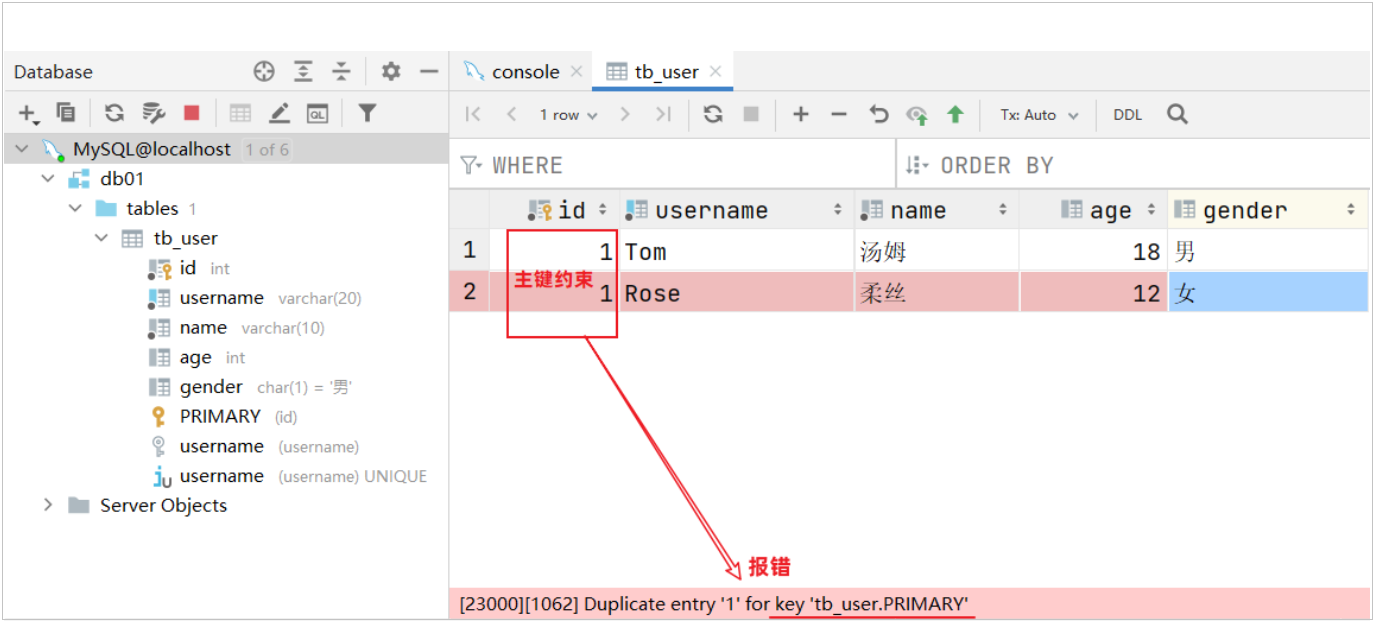

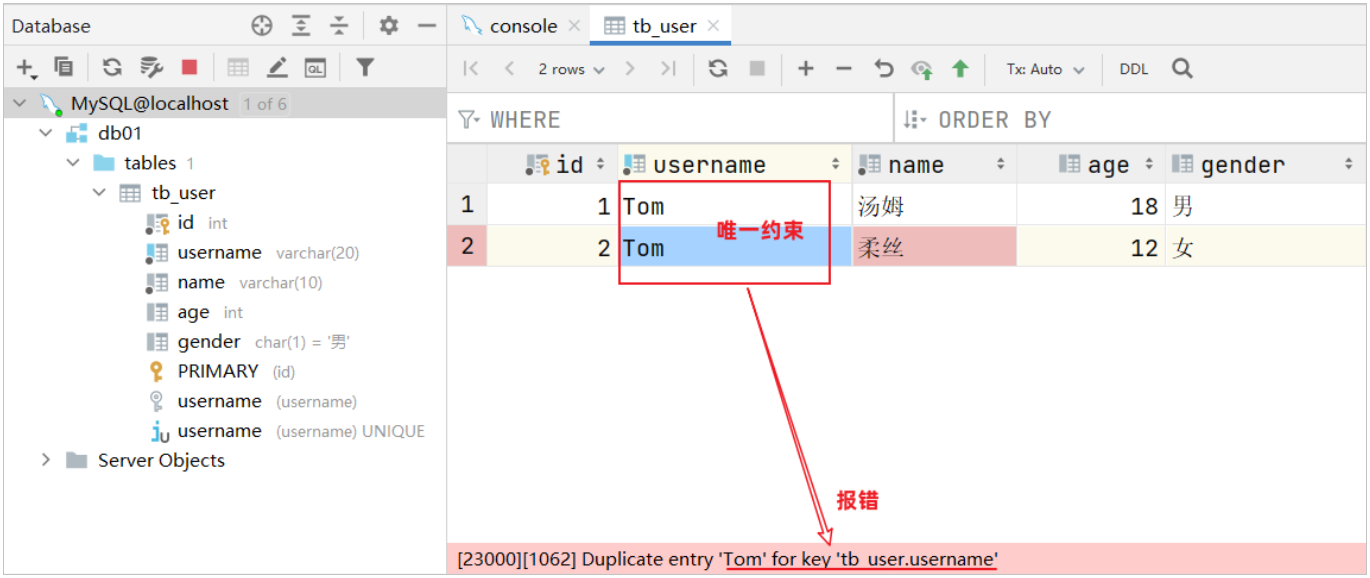

大家有没有发现一个问题：id字段下存储的值，如果由我们自己来维护会比较麻烦(必须保证值的唯一性)。MySQL数据库为了解决这个问题，给我们提供了一个关键字：auto&#95;increment（自动增长）

> <strong>主键自增：auto&#95;increment</strong>
> 
> - 每次插入新的行记录时，数据库自动生成id字段(主键)下的值
> - 具有auto&#95;increment的数据列是一个正数序列开始增长(从1开始自增)

````sql
create table tb_user (
    id int primary key auto_increment comment 'ID,唯一标识', #主键自动增长
    username varchar(20) not null unique comment '用户名',
    name varchar(10) not null comment '姓名',
    age int comment '年龄',
    gender char(1) default '男' comment '性别'
) comment '用户表';
````

> **补充：**自增列常与主键一起使用；插入时通常省略 id。它适合生成标识，但不保证无空洞、连续编号；插入失败、回滚或删除后都可能留下间隔，不应用“最大 id”代替行数。`AUTO_INCREMENT` 是列属性，不能代替唯一性约束本身。

测试主键自增：

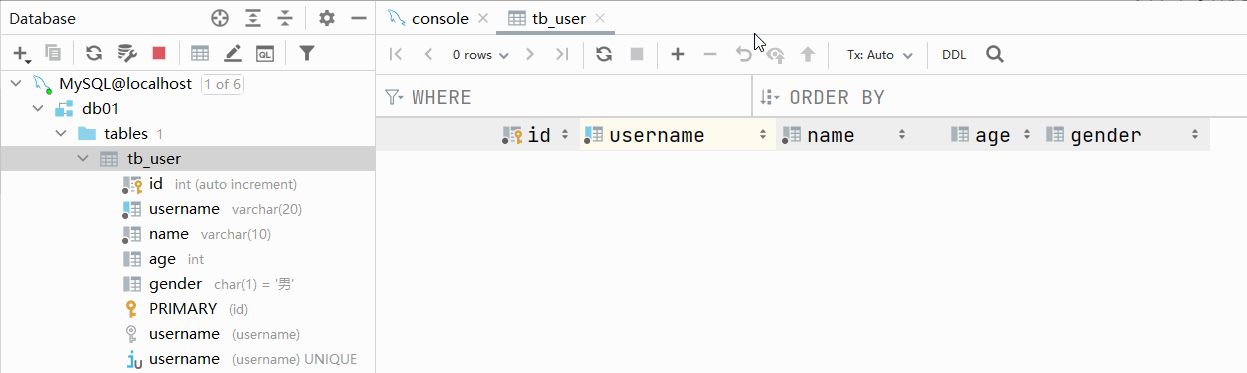


##### 3.1.3.3 数据类型

在上面建表语句中，我们在指定字段的数据类型时，用到了int 、varchar、char，那么在MySQL中除了以上的数据类型，还有哪些常见的数据类型呢？ 接下来,我们就来详细介绍一下MySQL的数据类型。

MySQL中的数据类型有很多，主要分为三类：数值类型、字符串类型、日期时间类型。

<strong>1). </strong><strong>数值类型</strong>

| 类型 | 大小 | 有符号(SIGNED)范围 | 无符号(UNSIGNED)范围 | 描述 |
| --- | --- | --- | --- | --- |
| TINYINT | 1byte | (-128，127) | (0，255) | 小整数值 |
| SMALLINT | 2bytes | (-32768，32767) | (0，65535) | 大整数值 |
| MEDIUMINT | 3bytes | (-8388608，8388607) | (0，16777215) | 大整数值 |
| INT/INTEGER | 4bytes | (-2147483648，2147483647) | (0，4294967295) | 大整数值 |
| BIGINT | 8bytes | (-2^63，2^63-1) | (0，2^64-1) | 极大整数值 |
| FLOAT | 4bytes | (-3.402823466 E+38，3.402823466351 E+38) | 0 和 (1.175494351 E-38，3.402823466 E+38) | 单精度浮点数值 |
| DOUBLE | 8bytes | (-1.7976931348623157 E+308，1.7976931348623157 E+308) | 0 和 (2.2250738585072014 E-308，1.7976931348623157 E+308) | 双精度浮点数值 |
| DECIMAL |  | 依赖于M(精度)和D(标度)的值 | 依赖于M(精度)和D(标度)的值 | 小数值(精确定点数) |

> **表格勘误：**整数范围两端均可取到，例如 TINYINT 为 -128～127，UNSIGNED TINYINT 为 0～255；原表的圆括号不是数学上的开区间。FLOAT/DOUBLE 是近似值，表中浮点范围写法不宜直接当完整精度规则；浮点/DECIMAL 的 UNSIGNED 声明也不建议用于新设计。DECIMAL(M,D) 的 M 是总位数、D 是小数位数，存储字节数取决于两者，不是“固定 8 字节”。

- 示例:

````sql
-- 年龄字段 ---不会出现负数, 而且人的年龄不会太大
   age tinyint unsigned

-- 分数 ---总分100分, 最多出现一位小数
   score double(4,1)
````

> **勘误：**这些是字段定义片段，不是独立 SQL。`DOUBLE(4,1)` 属于不推荐继续使用的旧式浮点精度写法，浮点数本身也不是精确小数。分数或金额需要精确小数时可用 `DECIMAL(4,1)`：4 是总位数、1 是小数位数，可以表示 100.0；但类型本身仍允许超过 100 的值，0～100 的业务范围需另外校验。

```sql
CREATE TABLE score_demo (
    score DECIMAL(4,1) NOT NULL,
    CONSTRAINT ck_score_range CHECK (score BETWEEN 0 AND 100)
);
```

本章 MySQL 8.0.34 会执行 CHECK 约束；MySQL 从 8.0.16 起才开始真正强制执行 CHECK。

<strong>2). </strong><strong>字符串类型</strong>

| 类型 | 大小 | 描述 |
| --- | --- | --- |
| CHAR | 0-255 bytes | 定长字符串(需要指定长度) |
| VARCHAR | 0-65535 bytes | 变长字符串(需要指定长度) |
| TINYBLOB | 0-255 bytes | 不超过255个字符的二进制数据 |
| TINYTEXT | 0-255 bytes | 短文本字符串 |
| BLOB | 0-65 535 bytes | 二进制形式的长文本数据 |
| TEXT | 0-65 535 bytes | 长文本数据 |
| MEDIUMBLOB | 0-16 777 215 bytes | 二进制形式的中等长度文本数据 |
| MEDIUMTEXT | 0-16 777 215 bytes | 中等长度文本数据 |
| LONGBLOB | 0-4 294 967 295 bytes | 二进制形式的极大文本数据 |
| LONGTEXT | 0-4 294 967 295 bytes | 极大文本数据 |

> **表格勘误：**`CHAR(M)`、`VARCHAR(M)` 的 M 对非二进制字符串表示**字符数**，不是字节数；CHAR 的 M 最大为 255，VARCHAR 的实际可用长度还受字符集、行大小和其他列影响，不能把表里的 65535 字节直接当作可写的字符数。utf8mb4 的一个字符最多需要 4 字节。BLOB 保存二进制字节，TEXT 保存有字符集的文本，TINYBLOB 的 255 是字节上限。
>
> CHAR 是定长语义、VARCHAR 是变长语义，但具体存储和性能还与引擎、字符集、数据长度有关，不能笼统认定 CHAR 总是更快。手机号、邮编等不是用来算术运算的值，通常使用字符串。

char 与 varchar 都可以描述字符串，char是定长字符串，指定长度多长，就占用多少个字符，和字段值的长度无关 。而varchar是变长字符串，指定的长度为最大占用长度 。相对来说，char的性能会更高些。

````sql
示例： 
    用户名 username ---长度不定, 最长不会超过50
    username varchar(50)
    
    手机号 phone ---固定长度为11
    phone char(11)
````

<strong>3). </strong><strong>日期时间类型</strong>

| 类型 | 大小 | 范围 | 格式 | 描述 |
| --- | --- | --- | --- | --- |
| DATE | 3 | 1000-01-01 至 9999-12-31 | YYYY-MM-DD | 日期值 |
| TIME | 3 | -838:59:59 至 838:59:59 | HH:MM:SS | 时间值或持续时间 |
| YEAR | 1 | 1901 至 2155 | YYYY | 年份值 |
| DATETIME | 8 | 1000-01-01 00:00:00 至 9999-12-31 23:59:59 | YYYY-MM-DD HH:MM:SS | 混合日期和时间值 |
| TIMESTAMP | 4 | 1970-01-01 00:00:01 至 2038-01-19 03:14:07 | YYYY-MM-DD HH:MM:SS | 混合日期和时间值，时间戳 |

> **表格勘误：**按 MySQL 8.0、无小数秒精度计算，DATE 占 3 字节、TIME 占 3 字节、YEAR 占 1 字节、DATETIME 占 **5 字节**、TIMESTAMP 占 4 字节；原表 DATETIME 的 8 字节是旧格式信息。指定小数秒精度时，TIME/DATETIME/TIMESTAMP 还会额外使用最多 3 字节。
>
> DATETIME 记录给定的日期时间值，不自动做会话时区转换；TIMESTAMP 会按会话时区与 UTC 相互转换，其表中范围是 UTC 范围。YEAR 还支持 0000；本章的入职日期只需 DATE。时间列不会仅因为名叫 create_time/update_time 就自动赋值。

````sql
示例: 
    生日字段  birthday ---生日只需要年月日  
    birthday date
    
    创建时间 createtime --- 需要精确到时分秒
    createtime  datetime
````


##### 3.1.3.4 表结构设计-案例

**补充：从原型到字段时，要区分存储规则和业务规则。**下方原型中，用户名要求 2～20 个字母、姓名要求 2～10 个汉字、手机号要求 11 位数字；仅用 `VARCHAR(20)`、`VARCHAR(10)`、`CHAR(11)` 并不能自动实现最小长度和字符内容校验。数据库约束与后端参数校验需要共同落实要求。

<strong>需求：</strong>根据产品原型/需求创建表((设计合理的数据类型、长度、约束) 

> 参考资料中提供的《黑马-tlias智能学习辅助系统》页面原型，设计员工管理模块的表结构。  <strong>暂不考虑所属部门及工作经历字段。</strong>

<strong>产品原型及需求如下：</strong>

1). 列表展示

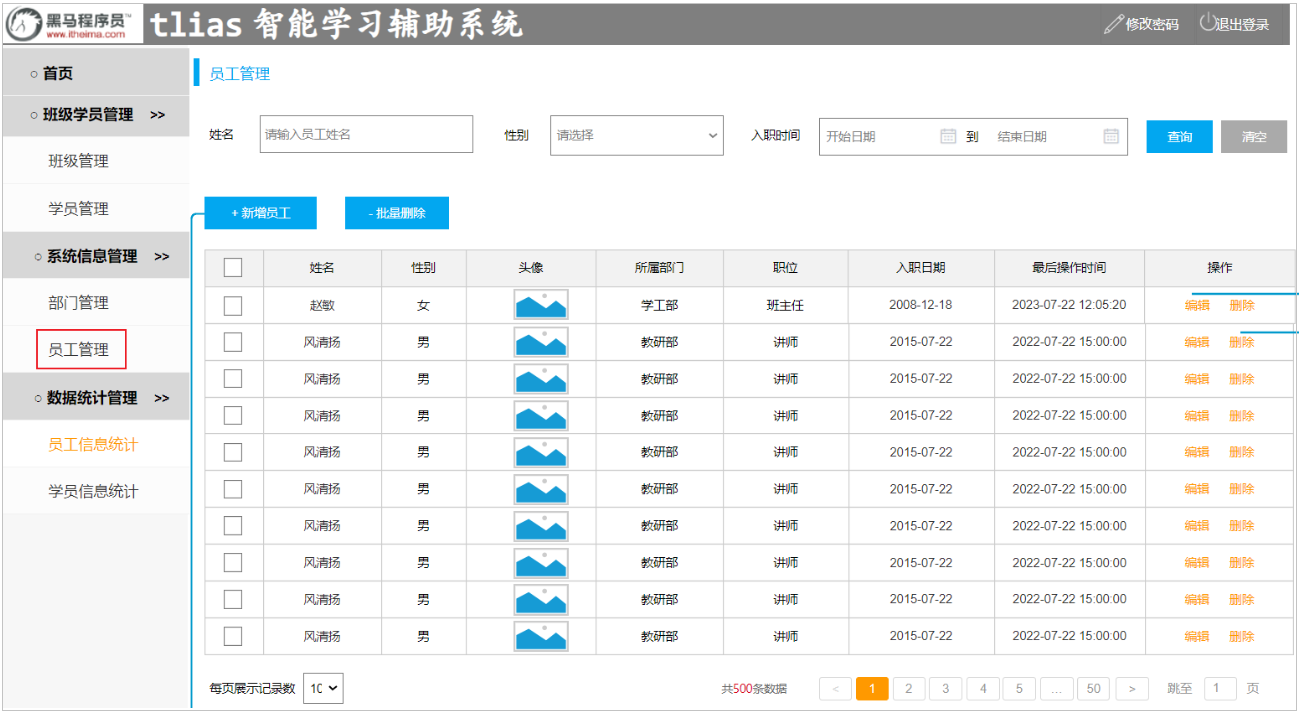

2). 新增员工

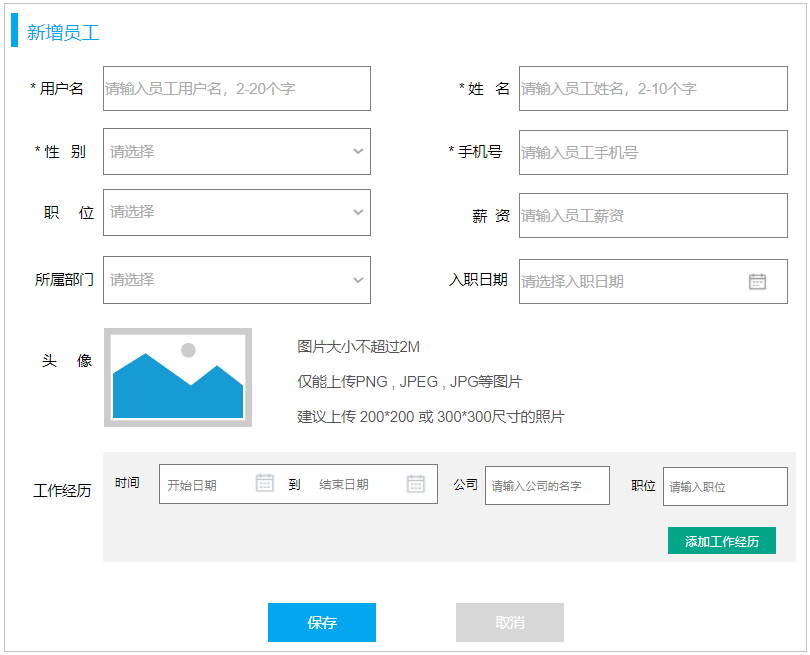

3). 需求说明及字段限制

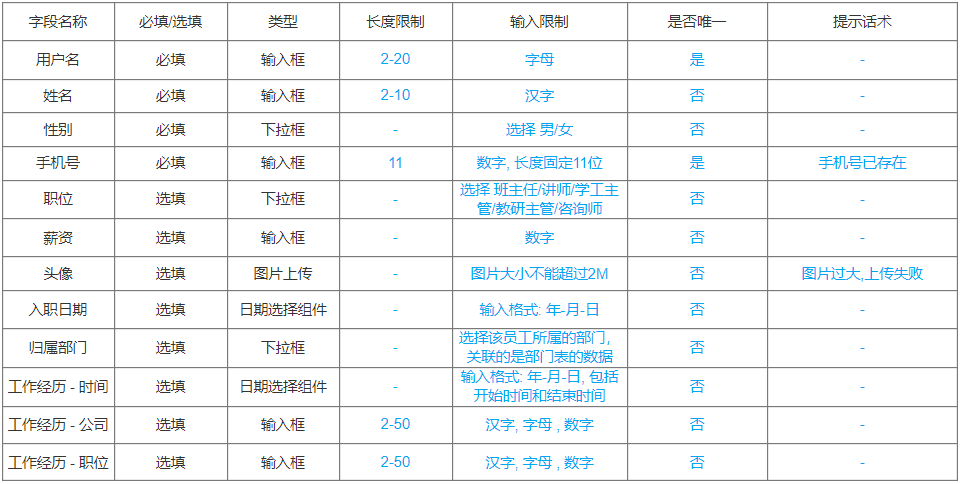

**配图需求转写：**

| 页面字段 | 必填/唯一 | 输入限制及落库要点 |
| --- | --- | --- |
| 用户名 | 必填、唯一 | 2～20 个字母；`username` 保存用户名 |
| 姓名 | 必填、不唯一 | 2～10 个汉字；`name` |
| 性别 | 必填 | 男/女；本章编码为 1/2，`NOT NULL` 不会自动限制只能填这两个值 |
| 手机号 | 必填、唯一 | 11 位数字；保存为字符串，避免丢失前导零等信息 |
| 职位 | 选填 | 班主任、讲师、学工主管、教研主管、咨询师，分别编码 1～5 |
| 薪资 | 选填 | 数字；本章用整数，涉及小数金额时考虑 `DECIMAL` |
| 头像 | 选填 | 上传图片不超过 2 MB；数据库的 image 字段保存路径/地址，长度不是图片大小 |
| 入职日期 | 选填 | 年-月-日，对应 `DATE` |
| 归属部门、工作经历 | 选填 | 原型还包括部门关联、经历开始/结束日期、公司、职位；本章暂不建模 |

工作经历中的公司、职位输入长度为 2～50，可包含汉字、字母、数字。`id`、`password`、`create_time`、`update_time` 则是本章表设计额外考虑的基础字段。

<strong>步骤：</strong>

1. 阅读产品原型及需求文档，看看里面涉及到哪些字段。
2. 查看需求文档说明，确认各个字段的类型以及字段存储数据的长度限制。
3. 在页面原型中描述的基础字段的基础上，再增加额外的基础字段。

使用SQL创建表：

````sql
create table emp(
    id int unsigned primary key auto_increment comment 'ID,主键',
    username varchar(20) not null unique comment '用户名',
    password varchar(32) not null comment '密码',
    name varchar(10) not null comment '姓名',
    gender tinyint unsigned not null comment '性别, 1:男, 2:女',
    phone char(11) not null unique comment '手机号',
    job tinyint unsigned comment '职位, 1:班主任,2:讲师,3:学工主管,4:教研主管,5:咨询师',
    salary int unsigned comment '薪资',
    image varchar(255) comment '头像',
    entry_date date comment '入职日期',
    create_time datetime comment '创建时间',
    update_time datetime comment '修改时间'
) comment '员工表';
````

> **补充：**这里的 `password` 为 `NOT NULL` 且没有默认值，因此后续 INSERT 必须提供它。`create_time`、`update_time` 在这份 DDL 中反而允许 NULL，也没有声明自动生成或自动更新；字段名不会让时间自动维护。原例的明文密码和 `VARCHAR(32)` 仅用于跟课，真实系统应保存合适算法生成的密码哈希并按编码长度设计字段。
>
> 本段 `image` 是 `VARCHAR(255)`，后文 DQL 建表片段改为 `VARCHAR(300)`。两段属于不同练习版本；第 6 节统一复用 DQL 的 300 版本。

除了使用SQL语句创建表外，我们还可以借助于图形化界面来创建表结构，这种创建方式会更加直观、更加方便。

> <strong>设计表流程：</strong>
> 
> 1. 阅读页面原型及需求文档
> 2. 基于页面原则和需求文档，确定原型字段(类型、长度限制、约束)
> 3. 再增加表设计所需要的业务基础字段(id、create&#95;time、update&#95;time)
> 
>     - create&#95;time：记录的是当前这条数据插入的时间。 
>     - update&#95;time：记录当前这条数据最后更新的时间。


##### 3.1.3.5 表操作-其他操作

> **勘误：**本节示例先对 `tb_emp` 做 ALTER，后面才把 `emp` 改名为 `tb_emp`；如果沿用上一节的表名，直接顺序执行会找不到表。以下保留原片段便于对照，第 6 节会用独立演示表串好顺序。`MODIFY`/`CHANGE` 修改列时，应完整写出希望保留的类型、NULL/默认值/注释等属性，避免遗漏。

上面讲解了表结构的创建、数据类型、设计表的流程，接下来，再来讲解表结构的查询、修改、删除操作 。 

- 查询数据库表的具体的语法：

````sql
-- 查询当前数据库的所有表
show tables;

-- 查看指定的表结构
desc 表名 ;   -- 可以查看指定表的字段、字段的类型、是否可以为NULL、是否存在默认值等信息

-- 查询指定表的建表语句
show create table 表名 ;
````

- 修改数据库表结构的具体语法：

添加字段

````sql
-- 添加字段
alter table 表名 add  字段名  类型(长度)  [comment 注释]  [约束];

-- 比如： 为tb_emp表添加字段qq，字段类型为 varchar(11)
alter table tb_emp add  qq  varchar(11) comment 'QQ号码';
````

修改字段

````sql
-- 修改字段类型
alter table 表名 modify  字段名  新数据类型(长度);

-- 比如： 修改qq字段的字段类型，将其长度由11修改为13
alter table tb_emp modify qq varchar(13) comment 'QQ号码';
````

````sql
-- 修改字段名，字段类型
alter table 表名 change  旧字段名  新字段名  类型(长度)  [comment 注释]  [约束];

-- 比如： 修改qq字段名为 qq_num，字段类型varchar(13)
alter table tb_emp change qq qq_num varchar(13) comment 'QQ号码';
````

删除字段

````sql
-- 删除字段
alter table 表名 drop 字段名;

-- 比如： 删除tb_emp表中的qq_num字段
alter table tb_emp drop qq_num;
````

修改表名

````sql
-- 修改表名
rename table 表名 to  新表名;

-- 比如: 将当前的emp表的表名修改为tb_emp
rename table emp to tb_emp;
````

删除表结构

````sql
-- 删除表
drop  table [ if exists ]  表名;

-- 比如：如果tb_emp表存在，则删除tb_emp表
drop table if exists tb_emp;  -- 在删除表时，表中的全部数据也会被删除。
````

> <strong>关于表结构的查看、修改、删除操作，工作中一般都是直接基于图形化界面操作。</strong><strong> </strong>


### 3.2 DML语句

DML英文全称是Data Manipulation Language(数据操作语言)，用来对数据库中表的数据记录进行增、删、改操作。

- 添加数据（INSERT）
- 修改数据（UPDATE）
- 删除数据（DELETE）


#### 3.2.1 增加(insert)


##### 3.2.1.1 语法

- 向指定字段添加数据

````sql
insert into 表名 (字段名1, 字段名2) values (值1, 值2);
````

- 全部字段添加数据

````sql
insert into 表名 values (值1, 值2, ...);
````

- 批量添加数据（指定字段）

````sql
insert into 表名 (字段名1, 字段名2) values (值1, 值2), (值1, 值2);
````

- 批量添加数据（全部字段）

````sql
insert into 表名 values (值1, 值2, ...), (值1, 值2, ...);
````


##### 3.2.1.2 案例演示

- 案例1：向emp表的username, name, gender, phone, create&#95;time, update&#95;time字段插入数据

````sql
-- 因为设计表时create_time, update_time两个字段不能为NULL，所以也做为要插入的字段
insert into emp(username, name, gender, phone, create_time, update_time)
values ('wuji', '张无忌', 1, '13309091231', now(), now());
````

**勘误：**原例漏了非空且无默认值的 `password`，在本章默认严格模式下会失败；原注释“两个时间字段不能为 NULL”也与实际 DDL 不符。匹配前述表结构的写法如下：

```sql
INSERT INTO emp(username, password, name, gender, phone, create_time, update_time)
VALUES ('wuji', '123456', '张无忌', 1, '13309091231', NOW(), NOW());
```

用户名和手机号需要满足唯一约束；重复执行不是“覆盖原行”，而是会发生唯一键冲突。

- 案例2：向temp表的所有字段插入数据

````sql
insert into emp2(id, username, password, name, gender, phone, job, salary, image, entry_date, create_time, update_time)
                  values (1,'shinaian','123456','施耐庵',1,'13309090001',4,15000,'1.jpg','2000-01-01',now(),now()),
````

**勘误：**说明中的 `temp`、代码中的 `emp2` 都与本章 `emp` 不一致，末尾逗号还表示语句未结束。在空的 emp 演示表中可这样写：

```sql
INSERT INTO emp(id, username, password, name, gender, phone, job, salary,
                image, entry_date, create_time, update_time)
VALUES (1, 'shinaian', '123456', '施耐庵', 1, '13309090001', 4, 15000,
        '1.jpg', '2000-01-01', NOW(), NOW());
```

这里显式写了全部列；若前一例已占用 id=1，这段会冲突。原文三项 INSERT 是独立演示，不应混同为一份连续的数据初始化脚本；第 6 节提供可按顺序练习的版本。

- 案例3：批量向emp表的username、name、gender字段插入数据

````sql
insert into emp(username, name, gender, phone, create_time, update_time)
values ('Tom1', '汤姆1', 1, '13309091231', now(), now()),
       ('Tom2', '汤姆2', 1, '13309091232', now(), now());
````

**勘误：**批量插入同样漏了 password；第一个手机号还与案例 1 重复。以下给出不与案例 1 手机号冲突的片段：

```sql
INSERT INTO emp(username, password, name, gender, phone, create_time, update_time)
VALUES ('Tom1', '123456', '汤姆1', 1, '13309091232', NOW(), NOW()),
       ('Tom2', '123456', '汤姆2', 1, '13309091233', NOW(), NOW());
```

这里的 `Tom1`、`汤姆1` 沿用 SQL 演示值，数据库当前约束允许它们；若严格执行上方原型“用户名只含字母、姓名只含汉字”的业务要求，应另外修改输入并加校验。

> <strong>insert操作的注意事项：</strong>
> 
> 1. 插入数据时，指定的字段顺序需要与值的顺序是一一对应的。
> 2. 字符串和日期型数据应该包含在引号中。
> 3. 插入的数据大小，应该在字段的规定范围内。


#### 3.2.2 修改(update)


##### 3.2.2.1 语法

````sql
update 表名 set 字段名1 = 值1 , 字段名2 = 值2 , .... [where 条件] ;
````


##### 3.2.2.2 案例演示

- 案例1：将emp表中id为1的员工，姓名name字段更新为'张三'

````sql
update emp set name='张三', update_time=now() where id=1;
````

- 案例2：将emp表的所有员工入职日期更新为'2010-01-01'

````sql
update emp set entry_date='2010-01-01', update_time=now();
````

> **跟练说明：**没有 WHERE 会修改所有行，这也会改变后续按入职日期查询的预期结果。先用同一条件 SELECT 确认目标，再在独立的演示表里执行；第 6 节将增删改练习与 30 行查询样本分开。

> <strong>注意事项:</strong>
> 
> 1. 修改语句的条件可以有，也可以没有，如果没有条件，则会修改整张表的所有数据。
> 2. 在修改数据时，一般需要同时修改公共字段update&#95;time，将其修改为当前操作时间。


#### 3.2.3 删除(delete)


##### 3.2.3.1 语法

````sql
delete from 表名  [where  条件] ;
````


##### 3.2.3.2 案例演示

- 案例1：删除emp表中id为1的员工

````sql
delete from emp where id = 1;
````

- 案例2：删除emp表中所有员工

````sql
delete from tb_emp;
````

> **勘误：**这里要演示清空 emp 的记录，原代码却写 `tb_emp`。按前文表名应为 `DELETE FROM emp;`，它保留表结构。客户端的确认弹窗并不是 MySQL 协议保证，命令行执行可能立即生效。`UPDATE 字段=NULL` 也只能用于允许 NULL 的字段。

> <strong>注意事项:</strong>
> 
> - DELETE 语句的条件可以有，也可以没有，如果没有条件，则会删除整张表的所有数据。
> - DELETE 语句不能删除某一个字段的值(可以使用UPDATE，将该字段值置为NULL即可)。
> - 当进行删除全部数据操作时，会提示询问是否确认删除所有数据，直接点击Execute即可。


### 3.3 DQL语句


#### 3.3.1 介绍

DQL英文全称是Data Query Language(数据查询语言)，用来查询数据库表中的记录。

查询关键字：<strong>SELECT</strong>

查询操作是所有SQL语句当中最为常见，也是最为重要的操作。在一个正常的业务系统中，查询操作的使用频次是要远高于增删改操作的。当我们打开某个网站或APP所看到的展示信息，都是通过从数据库中查询得到的，而在这个查询过程中，还会涉及到条件、排序、分页等操作。

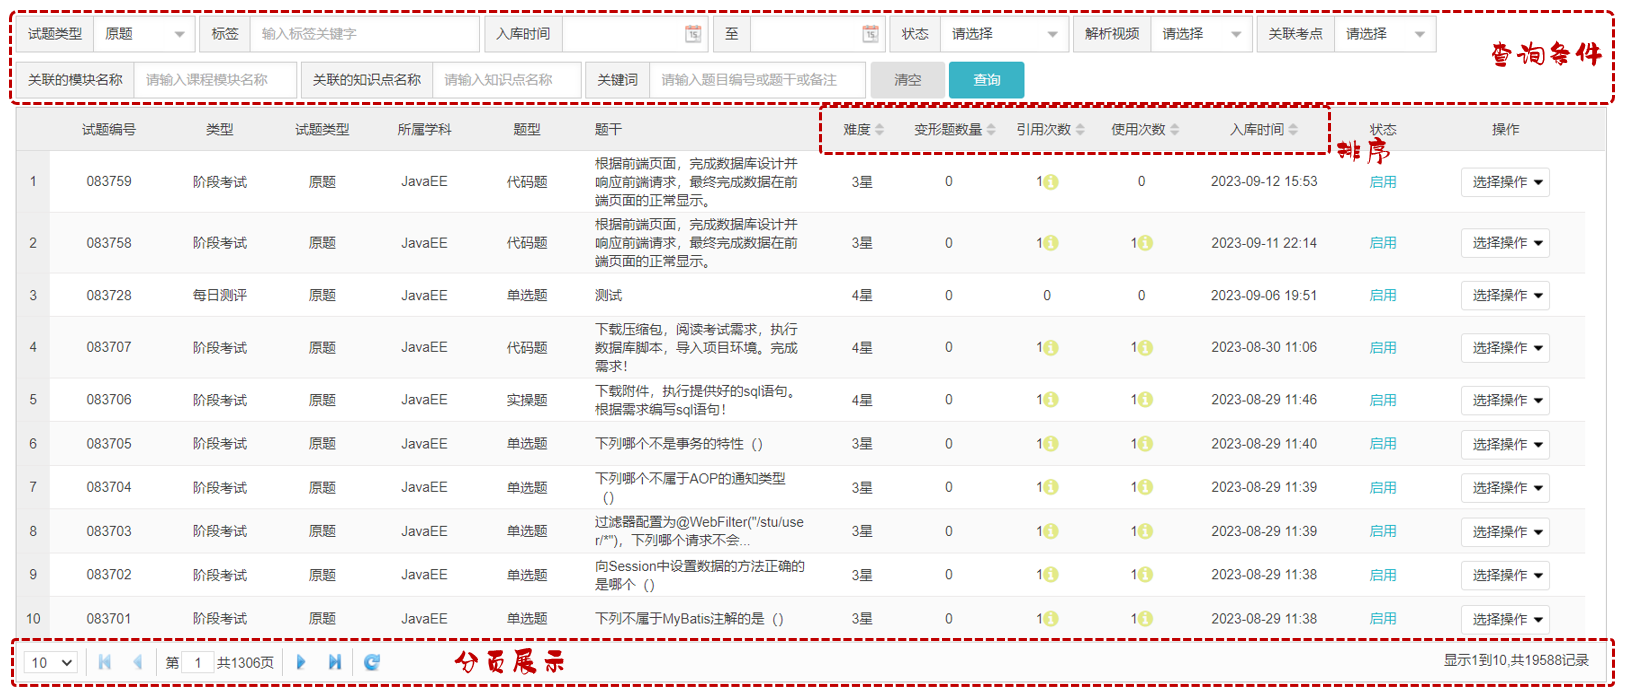


#### 3.3.2 语法

DQL查询语句，语法结构如下：

````sql
SELECT
        字段列表
FROM
        表名列表
WHERE
        条件列表
GROUP  BY
        分组字段列表
HAVING
        分组后条件列表
ORDER BY
        排序字段列表
LIMIT
        分页参数
````

我们今天会将上面的完整语法拆分为以下几个部分学习：

- 基本查询（不带任何条件）
- 条件查询（where）
- 分组查询（group by）
- 排序查询（order by）
- 分页查询（limit）

准备一些测试数据用于查询操作：

````sql
create table emp(
    id int unsigned primary key auto_increment comment 'ID,主键',
    username varchar(20) not null unique comment '用户名',
    password varchar(32) not null comment '密码',
    name varchar(10) not null comment '姓名',
    gender tinyint unsigned not null comment '性别, 1:男, 2:女',
    phone char(11) not null unique comment '手机号',
    job tinyint unsigned comment '职位, 1:班主任,2:讲师,3:学工主管,4:教研主管,5:咨询师',
    salary int unsigned comment '薪资',
    image varchar(300) comment '头像',
    entry_date date comment '入职日期',
    create_time datetime comment '创建时间',
    update_time datetime comment '修改时间'
) comment '员工表';


-- 准备测试数据
INSERT INTO emp(id, username, password, name, gender, phone, job, salary, image, entry_date, create_time, update_time)
VALUES (1,'shinaian','123456','施耐庵',1,'13309090001',4,15000,'1.jpg','2000-01-01','2024-04-11 16:35:33','2024-04-11 16:35:35'),
     (2,'songjiang','123456','宋江',1,'13309090002',2,8600,'2.jpg','2015-01-01','2024-04-11 16:35:33','2024-04-11 16:35:37'),
     (3,'lujunyi','123456','卢俊义',1,'13309090003',2,8900,'3.jpg','2008-05-01','2024-04-11 16:35:33','2024-04-11 16:35:39'),
     (4,'wuyong','123456','吴用',1,'13309090004',2,9200,'4.jpg','2007-01-01','2024-04-11 16:35:33','2024-04-11 16:35:41'),
     (5,'gongsunsheng','123456','公孙胜',1,'13309090005',2,9500,'5.jpg','2012-12-05','2024-04-11 16:35:33','2024-04-11 16:35:43'),
     (6,'huosanniang','123456','扈三娘',2,'13309090006',3,6500,'6.jpg','2013-09-05','2024-04-11 16:35:33','2024-04-11 16:35:45'),
     (7,'chaijin','123456','柴进',1,'13309090007',1,4700,'7.jpg','2005-08-01','2024-04-11 16:35:33','2024-04-11 16:35:47'),
     (8,'likui','123456','李逵',1,'13309090008',1,4800,'8.jpg','2014-11-09','2024-04-11 16:35:33','2024-04-11 16:35:49'),
     (9,'wusong','123456','武松',1,'13309090009',1,4900,'9.jpg','2011-03-11','2024-04-11 16:35:33','2024-04-11 16:35:51'),
     (10,'lichong','123456','林冲',1,'13309090010',1,5000,'10.jpg','2013-09-05','2024-04-11 16:35:33','2024-04-11 16:35:53'),
     (11,'huyanzhuo','123456','呼延灼',1,'13309090011',2,9700,'11.jpg','2007-02-01','2024-04-11 16:35:33','2024-04-11 16:35:55'),
     (12,'xiaoliguang','123456','小李广',1,'13309090012',2,10000,'12.jpg','2008-08-18','2024-04-11 16:35:33','2024-04-11 16:35:57'),
     (13,'yangzhi','123456','杨志',1,'13309090013',1,5300,'13.jpg','2012-11-01','2024-04-11 16:35:33','2024-04-11 16:35:59'),
     (14,'shijin','123456','史进',1,'13309090014',2,10600,'14.jpg','2002-08-01','2024-04-11 16:35:33','2024-04-11 16:36:01'),
     (15,'sunerniang','123456','孙二娘',2,'13309090015',2,10900,'15.jpg','2011-05-01','2024-04-11 16:35:33','2024-04-11 16:36:03'),
     (16,'luzhishen','123456','鲁智深',1,'13309090016',2,9600,'16.jpg','2010-01-01','2024-04-11 16:35:33','2024-04-11 16:36:05'),
     (17,'liying','12345678','李应',1,'13309090017',1,5800,'17.jpg','2015-03-21','2024-04-11 16:35:33','2024-04-11 16:36:07'),
     (18,'shiqian','123456','时迁',1,'13309090018',2,10200,'18.jpg','2015-01-01','2024-04-11 16:35:33','2024-04-11 16:36:09'),
     (19,'gudasao','123456','顾大嫂',2,'13309090019',2,10500,'19.jpg','2008-01-01','2024-04-11 16:35:33','2024-04-11 16:36:11'),
     (20,'ruanxiaoer','123456','阮小二',1,'13309090020',2,10800,'20.jpg','2018-01-01','2024-04-11 16:35:33','2024-04-11 16:36:13'),
     (21,'ruanxiaowu','123456','阮小五',1,'13309090021',5,5200,'21.jpg','2015-01-01','2024-04-11 16:35:33','2024-04-11 16:36:15'),
     (22,'ruanxiaoqi','123456','阮小七',1,'13309090022',5,5500,'22.jpg','2016-01-01','2024-04-11 16:35:33','2024-04-11 16:36:17'),
     (23,'ruanji','123456','阮籍',1,'13309090023',5,5800,'23.jpg','2012-01-01','2024-04-11 16:35:33','2024-04-11 16:36:19'),
     (24,'tongwei','123456','童威',1,'13309090024',5,5000,'24.jpg','2006-01-01','2024-04-11 16:35:33','2024-04-11 16:36:21'),
     (25,'tongmeng','123456','童猛',1,'13309090025',5,4800,'25.jpg','2002-01-01','2024-04-11 16:35:33','2024-04-11 16:36:23'),
     (26,'yanshun','123456','燕顺',1,'13309090026',5,5400,'26.jpg','2011-01-01','2024-04-11 16:35:33','2024-04-11 16:36:25'),
     (27,'lijun','123456','李俊',1,'13309090027',5,6600,'27.jpg','2004-01-01','2024-04-11 16:35:33','2024-04-11 16:36:27'),
     (28,'lizhong','123456','李忠',1,'13309090028',5,5000,'28.jpg','2007-01-01','2024-04-11 16:35:33','2024-04-11 16:36:29'),
     (29,'songqing','123456','宋清',1,'13309090029',5,5100,'29.jpg','2020-01-01','2024-04-11 16:35:33','2024-04-11 16:36:31'),
     (30,'liyun','123456','李云',1,'13309090030',NULL,NULL,'30.jpg','2020-03-01','2024-04-11 16:35:33','2024-04-11 16:36:31');
````

> **补充：**这段包含建表和 30 行初始化数据，要求当前库里还没有同名 emp 表。前面的 DDL/DML 演示可能已经创建或改动它；推荐在第 6 节指定的新练习库中执行此段一次。`CREATE TABLE IF NOT EXISTS` 只能跳过已存在的表，不能把旧结构自动升级成新结构，也不能防止重复 INSERT。


#### 3.3.3 基本查询

在基本查询的DQL语句中，不带任何的查询条件。

<strong>语法如下：</strong>

- 查询多个字段

````sql
select 字段1, 字段2, 字段3 from  表名;
````

- 查询所有字段（通配符）

````sql
select *  from  表名;
````

- 设置别名

````sql
select 字段1 [ as 别名1 ] , 字段2 [ as 别名2 ]  from  表名;
````

- 去除重复记录

````sql
select distinct 字段列表 from  表名;
````

<strong>案例演示:</strong>

- 案例1：查询指定字段 name，entry&#95;date并返回

````sql
select name,entry_date from emp;
````

- 案例2：查询返回所有字段

````sql
select * from emp;
````

> &#42; 号代表查询所有字段，在实际开发中尽量少用（不直观、影响效率）

- 案例3：查询所有员工的 name, entry&#95;date，并起别名(姓名、入职日期)

````sql
-- 方式1：
select name AS 姓名, entry_date AS 入职日期 from emp;

-- 方式2： 别名中有特殊字符时，使用''或""包含
select name AS '姓 名', entry_date AS '入职日期' from emp;

-- 方式3：
select name AS "姓名", entry_date AS "入职日期" from emp;
````

> **补充：**MySQL 支持在 SELECT 列表里用字符串引号定义别名，但后续引用带空格的别名时应使用反引号，例如 <code>ORDER BY &#96;姓 名&#96;</code>。单引号形式在表达式中通常表示字符串常量。为减少混淆，别名推荐不含空格，例如 `name AS employee_name`。

- 案例4：查询已有的员工关联了哪几种职位(不要重复)

````sql
select distinct job from emp;
````

> **补充：**`DISTINCT` 去重的是 SELECT 中的整组列，不是只对第一列去重。这里结果包括职位 1～5 和一项 NULL，共 6 种；显示顺序不受保证。


#### 3.3.4 条件查询

<strong>语法：</strong>

````sql
select  字段列表  from   表名   where   条件列表 ; -- 条件列表：意味着可以有多个条件
````

学习条件查询就是学习条件的构建方式，而在SQL语句当中构造条件的运算符分为两类：

- 比较运算符
- 逻辑运算符

常用的比较运算符如下: 

| 比较运算符 | 功能 |
| --- | --- |
| &gt; | 大于 |
| &gt;= | 大于等于 |
| &lt; | 小于 |
| &lt;= | 小于等于 |
| = | 等于 |
| &lt;&gt; 或 != | 不等于 |
| between ... and ... | 在某个范围之内(含最小、最大值) |
| in(...) | 在in之后的列表中的值，多选一 |
| like 占位符 | 模糊匹配(&#95;匹配单个字符, %匹配任意个字符) |
| is null | 是null |

> **补充：**`BETWEEN` 包含两端。本章 entry_date 是 DATE；若以后换成含时分秒的 DATETIME，查询一整天通常用 `>= 当天零点 AND < 次日零点`。NULL 表示未知/缺失，与空字符串、0 不同；用 IS NULL / IS NOT NULL 判断。`NOT IN` 列表含 NULL 时可能使你期待保留的行被过滤，不能把 NULL 当普通值比较。

常用的逻辑运算符如下:

| 逻辑运算符 | 功能 |
| --- | --- |
| and 或 &amp;&amp; | 并且 (多个条件同时成立) |
| or 或 &#124;&#124; | 或者 (多个条件任意一个成立) |
| not 或 ! | 非 , 不是 |

> **补充：**推荐写 AND、OR、NOT。`||` 在某些 SQL 模式下表示字符串连接，且符号别名存在兼容性问题。AND 的优先级高于 OR；混合条件建议加括号明确业务含义，例如 `(job = 2 OR job = 3) AND salary > 5000`。

- 案例1：查询 姓名 为 '杨逍' 的员工

````sql
select id, username, password, name, gender, phone, salary, job, image, entry_date, create_time, update_time
from emp
where name = '杨逍'; -- 字符串使用''或""包含
````

> **跟练对照：**这份 30 行样本中没有“杨逍”，查询应返回 0 行，不能据此认定 SQL 写错。改成 `name = '宋江'` 可找到 id=2。相同地，后面的 `name LIKE '张%'` 在这份未改动的样本中也返回 0 行。

- 案例2：查询 薪资小于等于 5000 的员工信息

````sql
select id, username, password, name, gender, phone, salary, job, image, entry_date, create_time, update_time
from emp
where salary <=5000;
````

- 案例3：查询 没有分配职位 的员工信息

````sql
select id, username, password, name, gender, phone, salary, job, image, entry_date, create_time, update_time
from emp
where job is null ;
````

> 注意：查询为NULL的数据时，不能使用 <code>= null</code> 或 <code>！=null</code> 。得使用 <code>is null</code> 或 <code>is not null</code>。

- 案例4：查询 有职位 的员工信息

````sql
select id, username, password, name, gender, phone, salary, job, image, entry_date, create_time, update_time
from emp
where job is not null ;
````

- 案例5：查询 密码不等于 '123456' 的员工信息

````sql
-- 方式1：
select id, username, password, name, gender, phone, salary, job, image, entry_date, create_time, update_time
from emp
where password <> '123456';
````

````sql
-- 方式2：
select id, username, password, name, gender, phone, salary, job, image, entry_date, create_time, update_time
from emp
where password != '123456';
````

- 案例6：查询 入职日期 在  '2000-01-01' (包含)  到  '2010-01-01'(包含) 之间的员工信息

````sql
-- 方式1：
select id, username, password, name, gender, phone, salary, job, image, entry_date, create_time, update_time
from emp
where entry_date >= '2000-01-01' and entry_date <= '2010-01-01';

-- 方式2： between...and
select id, username, password, name, gender, phone, salary, job, image, entry_date, create_time, update_time
from emp
where entry_date between '2000-01-01' and '2010-01-01';
````

- 案例7：查询 入职时间 在 '2000-01-01' (包含) 到 '2010-01-01'(包含) 之间 且 性别为女 的员工信息

````sql
select id, username, password, name, gender, phone, salary, job, image, entry_date, create_time, update_time
from emp
where entry_date between '2000-01-01' and '2010-01-01';
      and gender = 2;
````

**勘误：**日期条件后的分号提前结束了 SELECT，下一行 AND 因而报语法错误。分号应放在整个条件末尾：

```sql
SELECT id, name, gender, entry_date
FROM emp
WHERE entry_date BETWEEN '2000-01-01' AND '2010-01-01'
  AND gender = 2;
```

使用本章原始 30 行样本时，应只得到 id=19 的顾大嫂。

- 案例8：查询 职位是 2 (讲师), 3 (学工主管), 4 (教研主管) 的员工信息

````sql
-- 方式1：使用or连接多个条件
select id, username, password, name, gender, phone, salary, job, image, entry_date, create_time, update_time
from emp
where job=2 or job=3 or job=4;

-- 方式2：in关键字
select id, username, password, name, gender, phone, salary, job, image, entry_date, create_time, update_time
from emp
where job in (2,3,4);
````

- 案例9：查询 姓名 为两个字的员工信息

````sql
select id, username, password, name, gender, phone, salary, job, image, entry_date, create_time, update_time
from emp
where name like '__';  # 通配符 "_" 代表任意1个字符
````

- 案例10：查询 姓 '张' 的员工信息

````sql
select id, username, password, name, gender, phone, salary, job, image, entry_date, create_time, update_time
from emp
where name like '张%'; # 通配符 "%" 代表任意个字符（0个 ~ 多个）
````

- 案例11：查询 姓名中包含 '二'  的员工信息

````sql
select id, username, password, name, gender, phone, salary, job, image, entry_date, create_time, update_time
from emp
where name like '%二%'; # 通配符 "%" 代表任意个字符（0个 ~ 多个）
````


#### 3.3.5 聚合函数

> **勘误：**不能把“聚合函数忽略 NULL”理解为所有 COUNT 都跳过整行：`COUNT(*)` 统计行数，`COUNT(字段)` 只数该字段非 NULL 的行。`COUNT(NULL)` 得到 0；非空常量写法如 `COUNT(1)` 仍统计行数。`SUM`/`AVG` 不把 NULL 当 0，没有可统计的非 NULL 值时通常返回 NULL，COUNT 则返回 0。
>
> “不是数值类型，SUM 结果就是 0”不准确：MySQL 可能进行隐式数值转换并产生警告。应对数值列求和，避免依赖字符串转换。本例 salary 有一条 NULL，平均薪资的分母是 29，而不是 30；`COUNT(*)` 与 `COUNT(1)` 也不应一概比较为前者必定更快。

之前我们做的查询都是横向查询，就是根据条件一行一行的进行判断，而使用聚合函数查询就是纵向查询，它是对一列的值进行计算，然后返回一个结果值。（将一列数据作为一个整体，进行纵向计算）

常用聚合函数：

| 函数 | 功能 |
| --- | --- |
| count | 统计数量 |
| max | 最大值 |
| min | 最小值 |
| avg | 平均值 |
| sum | 求和 |

> 注意 : 聚合函数会忽略空值，对NULL值不作为统计。

- count ：按照列去统计有多少行数据。

    - 在根据指定的列统计的时候，如果这一列中有null的行，该行不会被统计在其中。
- sum ：计算指定列的数值和，如果不是数值类型，那么计算结果为0
- max ：计算指定列的最大值
- min ：计算指定列的最小值
- avg ：计算指定列的平均值

<strong>案例演示:</strong>

- 案例1：统计该企业员工数量

````sql
-- count(字段)
select count(id) from emp;-- 结果：30
select count(job) from emp;-- 结果：29 （聚合函数对NULL值不做计算）

-- count(常量)
select count(0) from emp;
select count('A') from emp;

-- count(*)  推荐此写法（MySQL底层进行了优化）
select count(*) from emp;
````

- 案例2：统计该企业员工的平均薪资

````sql
select avg(salary) from  emp;
````

- 案例3：统计该企业员工的最低薪资

````sql
select min(salary) from emp;
````

- 案例4：统计该企业员工的最高薪资

````sql
select max(salary) from emp;
````

- 案例5：统计该企业每月要给员工发放的薪资总额(薪资之和)

````sql
select sum(salary) from emp;
````


#### 3.3.6 分组查询

**补充：按逻辑处理顺序理解分组。**

```text
FROM 取行 → WHERE 筛行 → GROUP BY 分组/聚合
         → HAVING 筛组 → SELECT 生成结果列 → ORDER BY 排序 → LIMIT 取页
```

这是理解结果的逻辑顺序，优化器实际执行计划可能不同。`WHERE salary > 5000` 检查每行；`HAVING AVG(salary) > 5000` 检查每组汇总结果。默认开启 `ONLY_FULL_GROUP_BY` 时，不能随意混选与分组无关的非聚合列；MySQL 也允许能由分组键唯一决定的列，但本章先按“分组列 + 聚合列”书写。

- 分组： 按照某一列或者某几列，把相同的数据进行合并输出。

    - 分组其实就是按列进行分类(指定列下相同的数据归为一类)，然后可以对分类完的数据进行合并计算。
    - 分组查询通常会使用聚合函数进行计算。

<strong>语法：</strong>

````sql
select  字段列表  from  表名  [where 条件]  group by 分组字段名  [having 分组后过滤条件];
````

<strong>案例演示：</strong>

- 案例1：根据性别分组 , 统计男性和女性员工的数量

````sql
select gender, count(*)
from emp
group by gender; -- 按照gender字段进行分组（gender字段下相同的数据归为一组）
````

- 案例2：查询入职时间在 '2015-01-01' (包含) 以前的员工 , 并对结果根据职位分组 , 获取员工数量大于等于2的职位

````sql
select job, count(*)
from emp
where entry_date <= '2015-01-01'   -- 分组前条件
group by job                      -- 按照job字段分组
having count(*) >= 2;             -- 分组后条件
````

> <strong>注意事项:</strong>
> 
> - 分组之后，查询的字段一般为聚合函数和分组字段，查询其他字段无任何意义
> - 执行顺序：where &gt; 聚合函数 &gt; having 

> <strong>where与having区别（面试题）</strong>
> 
> - 执行时机不同：where是分组之前进行过滤，不满足where条件，不参与分组；而having是分组之后对结果进行过滤。
> - 判断条件不同：where不能对聚合函数进行判断，而having可以。


#### 3.3.7 排序查询

> **勘误：**原讲义小节名“排查查询”应为“排序查询”，本笔记标题已修正。多字段排序中，后面的字段只在前面字段相等时决定顺序。

排序在日常开发中是非常常见的一个操作，有升序排序，也有降序排序。

<strong>语法：</strong>

````sql
select  字段列表  
from   表名   
[where  条件列表] 
[group by  分组字段 ] 
order  by  字段1  排序方式1 , 字段2  排序方式2 … ;
````

- 排序方式：

    - ASC ：升序（默认值）
    - DESC：降序

<strong>案例演示：</strong>

- 案例1：根据入职时间, 对员工进行升序排序

````sql
select id, username, password, name, gender, phone, salary, job, image, entry_date, create_time, update_time
from emp
order by entry_date ASC; -- 按照entrydate字段下的数据进行升序排序

select id, username, password, name, gender, phone, salary, job, image, entry_date, create_time, update_time
from emp
order by  entry_date; -- 默认就是ASC（升序）
````

> 注意事项：如果是升序, 可以不指定排序方式ASC 

- 案例2：根据入职时间，对员工进行降序排序

````sql
select id, username, password, name, gender, phone, salary, job, image, entry_date, create_time, update_time
from emp
order by entry_date DESC; -- 按照entrydate字段下的数据进行降序排序
````

- 案例3：根据入职时间对公司的员工进行升序排序，入职时间相同，再按照更新时间进行降序排序

````sql
select id, username, password, name, gender, phone, salary, job, image, entry_date, create_time, update_time
from emp
order by entry_date ASC , update_time DESC;
````

> 注意事项：如果是多字段排序，当第一个字段值相同时，才会根据第二个字段进行排序


#### 3.3.8 分页查询

**补充：分页先确定排序，再计算偏移。**`LIMIT 5, 5` 中第一个 5 表示跳过 5 行，不表示从 id=5 开始。原例未写 ORDER BY，返回哪一批行没有稳定保证；跟练时可按唯一主键排序：

```sql
-- 第 2 页，每页 5 条：offset = (2 - 1) * 5 = 5
SELECT id, name FROM emp ORDER BY id LIMIT 5, 5;
```

对本章样本应得到 id=6～10。按非唯一字段如薪资分页时，可追加 `id` 作为同值时的次级排序键；分页期间数据若发生变化，偏移分页仍可能重复或漏行。

分页操作在业务系统开发时，也是非常常见的一个功能，日常我们在网站中看到的各种各样的分页条，后台也都需要借助于数据库的分页操作。

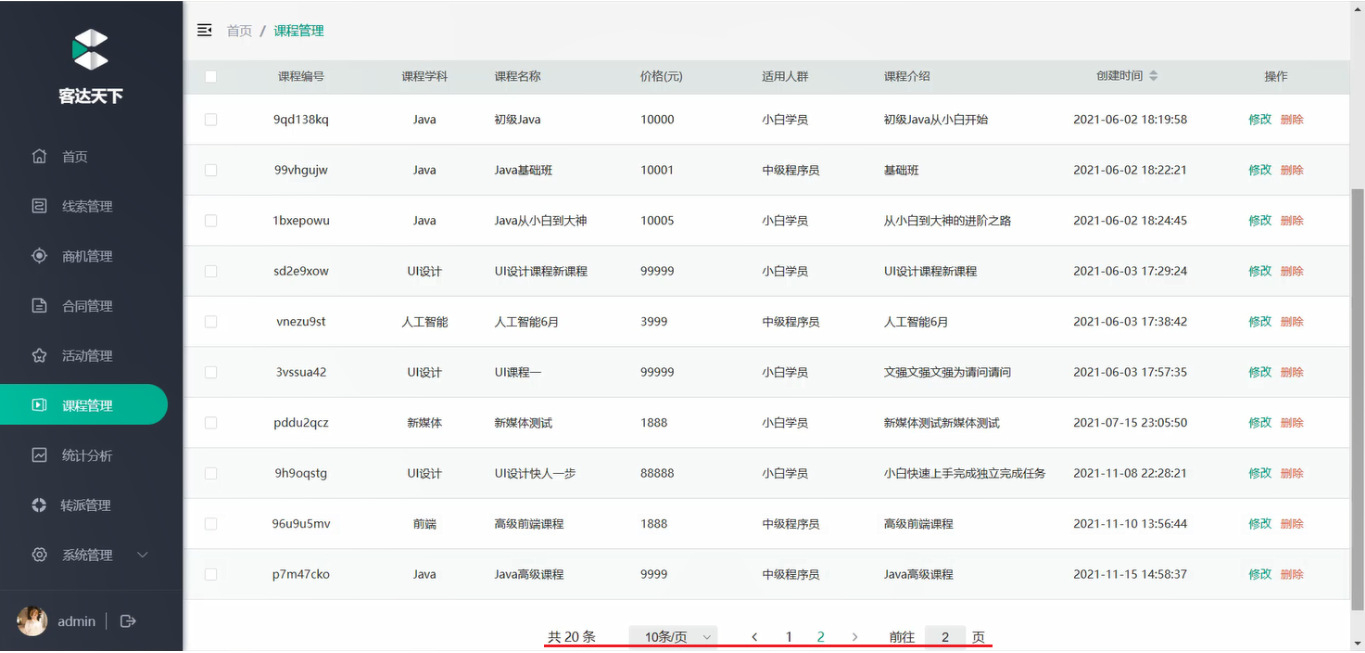

分页查询语法：

````sql
select  字段列表  from  表名  limit  起始索引, 查询记录数 ;
````

- 案例1：从起始索引0开始查询员工数据, 每页展示5条记录

````sql
select id, username, password, name, gender, phone, salary, job, image, entry_date, create_time, update_time
from emp
limit 0 , 5; -- 从索引0开始，向后取5条记录
````

- 案例2：查询 第1页 员工数据, 每页展示5条记录

````sql
select id, username, password, name, gender, phone, salary, job, image, entry_date, create_time, update_time
from emp
limit 5; -- 如果查询的是第1页数据，起始索引可以省略，直接简写为：limit 条数
````

- 案例3：查询 第2页 员工数据, 每页展示5条记录

````sql
select id, username, password, name, gender, phone, salary, job, image, entry_date, create_time, update_time
from emp
limit 5 , 5; -- 从索引5开始，向后取5条记录
````

- 案例4：查询 第3页 员工数据, 每页展示5条记录

````sql
select id, username, password, name, gender, phone, salary, job, image, entry_date, create_time, update_time
from emp
limit 10 , 5; -- 从索引10开始，向后取5条记录
````

> <strong>注意事项:</strong>
> 
> 1. 起始索引从0开始。           计算公式 ：起始索引 = （查询页码 - 1）&#42; 每页显示记录数
> 2. 分页查询是数据库的方言，不同的数据库有不同的实现，MySQL中是LIMIT
> 3. 如果查询的是第一页数据，起始索引可以省略，直接简写为 limit  条数


## 4 附录：MySQL 安装与连接

本节并入课程 [MySQL 安装文档](https://heuqqdmbyk.feishu.cn/wiki/ZRSFwACsRiBD2NkV7bmcrJhInme)，对应 Windows ZIP 包安装方式。已能连接 MySQL 的读者可跳过安装，直接验证 `SELECT VERSION();`。以下命令是供读者按需操作的说明，本次笔记整理没有修改本机数据库环境。


### 4.1 解压

下载完成后我们得到的是一个压缩包，将其解压，我们就可以得到MySQL 8.0.34 的软件本体了(就是一个文件夹)，我们可以把它放在你想安装的位置 。

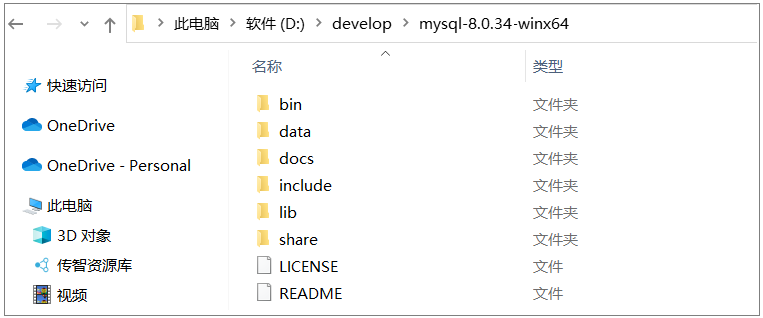


### 4.2 配置


#### 4.2.1 添加环境变量

> **勘误：**CMD 的查找过程不能概括为“先找 Path，找不到才找当前目录”，当前目录通常先于 PATH；PowerShell 对当前目录程序通常要显式写 `.\mysql.exe`。不论哪种 Shell，PATH 的用途都是帮助定位可执行文件。

**配图配置转写：**`MYSQL_HOME` 指向实际解压目录，例如 `D:\develop\mysql-8.0.34-winx64`；在 Path 增加 `%MYSQL_HOME%\bin`。`MYSQL_HOME` 只是方便引用的变量，不是必须的特殊变量；也可直接把 bin 的绝对路径加入 Path。修改后重新打开终端，用 `mysql --version` 检查命令是否可找到。

> 环境变量里面有很多选项，这里我们只用到<code>Path</code>这个参数。为什么在初始化的开始要添加环境变量呢？
> 
> 在黑框(即CMD)中输入一个可执行程序的名字，Windows会先在环境变量中的<code>Path</code>所指的路径中寻找一遍，如果找到了就直接执行，没找到就在当前工作目录找，如果还没找到，就报错。我们添加环境变量的目的就是能够在任意一个黑框直接调用MySQL中的相关程序而不用总是修改工作目录，大大简化了操作。

右键<strong><code>此电脑</code></strong>→<strong><code>属性</code></strong>，点击<strong><code>高级系统设置</code></strong>

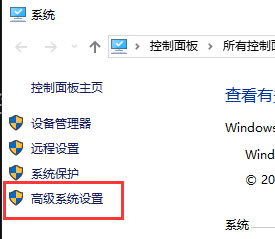

点击<strong><code>环境变量</code></strong>

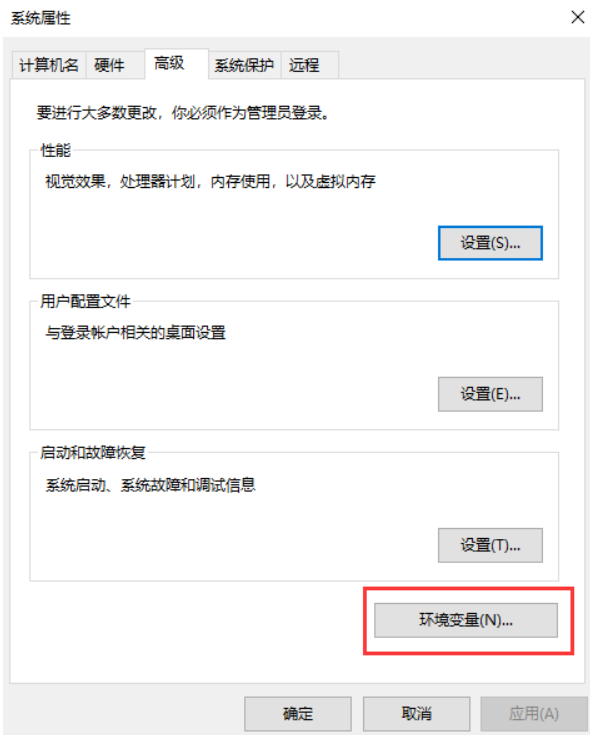

在<strong><code>系统变量</code></strong>中新建<code>MYSQL&#95;HOME</code>

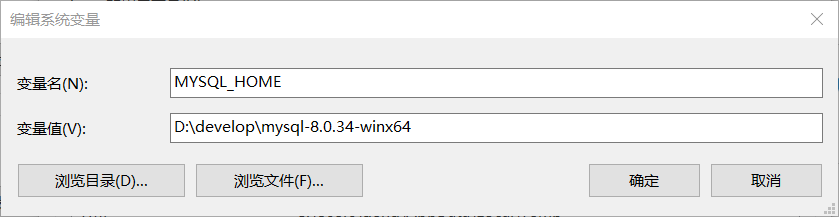

在<strong><code>系统变量</code></strong>中找到并<strong>双击</strong><strong><code>Path</code></strong>

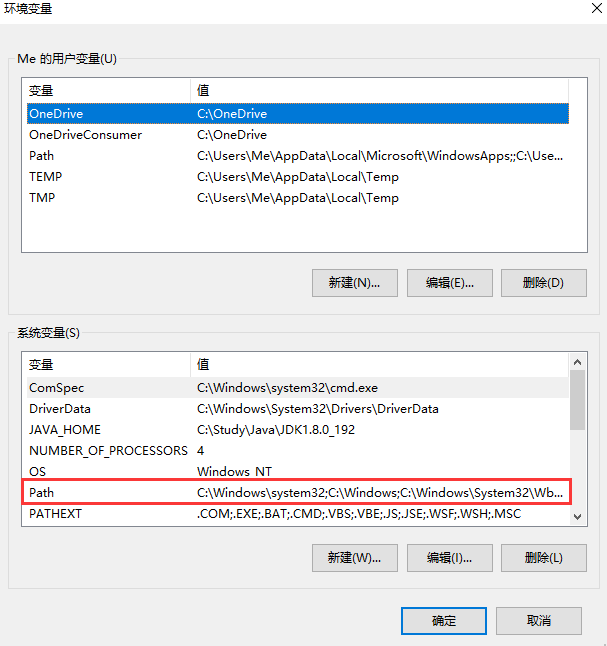

点击<strong><code>新建</code></strong>

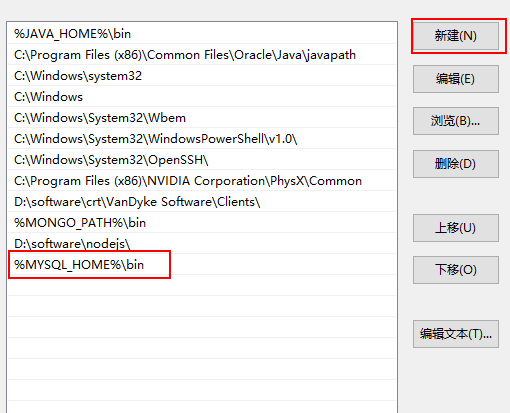

最后点击确定。

<strong>如何验证是否添加成功？</strong>

右键开始菜单(就是屏幕左下角)，选择<strong><code>命令提示符(管理员)</code></strong>，打开黑框，敲入<strong><code>mysql</code></strong>，回车。

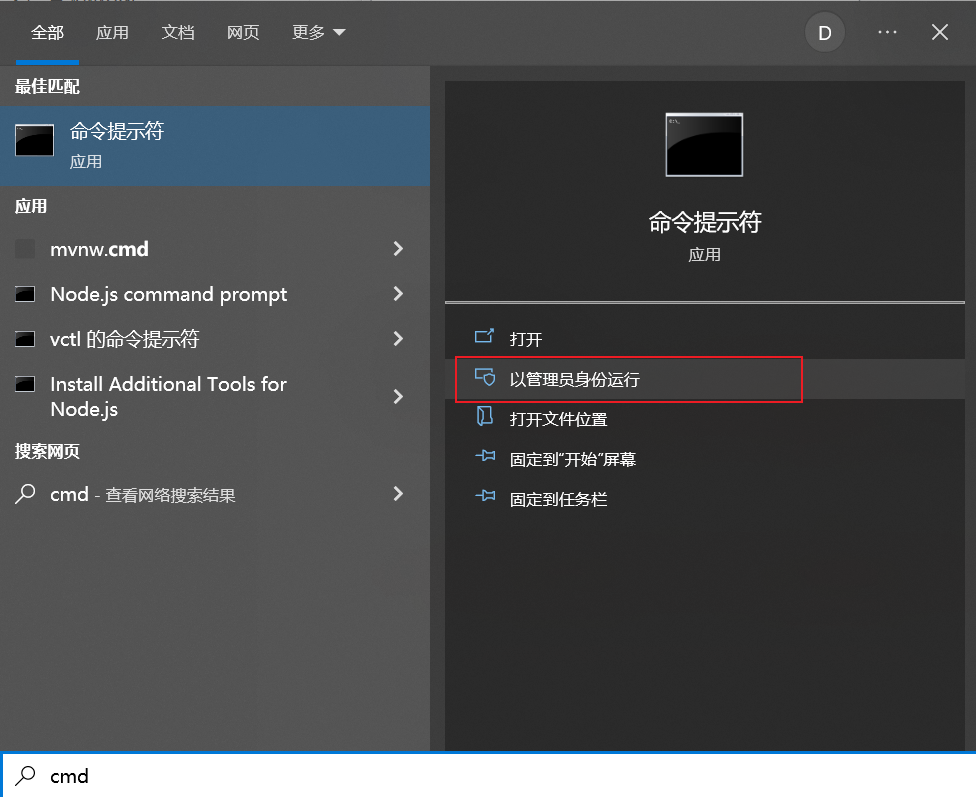

如果提示<code>Can't connect to MySQL server on '</code><code>localhost</code><code>'</code>则证明添加成功；

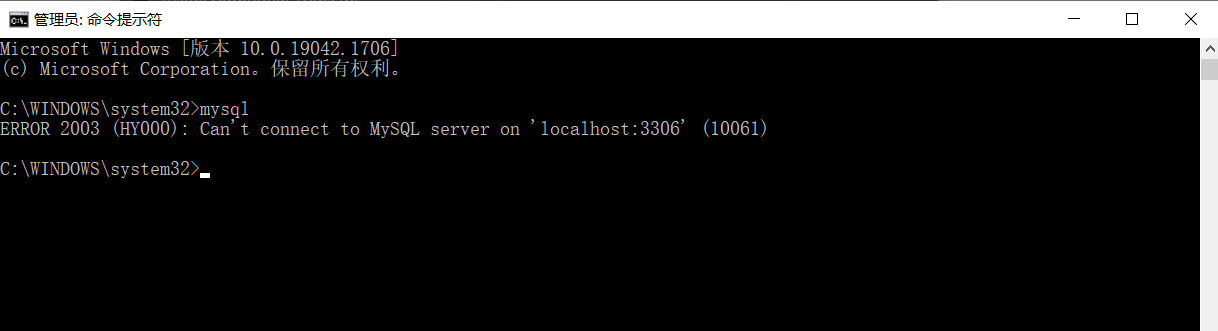

如果提示<code>mysql不是内部或外部命令，也不是可运行的程序或批处理文件</code>则表示添加添加失败，请重新检查步骤并重试。


#### 4.2.2 初始化

> **补充：**`mysqld` 是服务端程序，`mysql` 是客户端。以下初始化命令在 Windows 终端执行，不在 `mysql>` 中执行；原讲义代码块的 SQL 标记不代表它是 SQL。`--initialize-insecure` 会初始化一个空密码 root 账号，只适用于新的数据目录。已有实例不要再次初始化，更不要为了通过初始化而删除已有 data 目录；以命令退出状态和错误日志判断是否成功。

以管理员身份，运行命令行窗口：

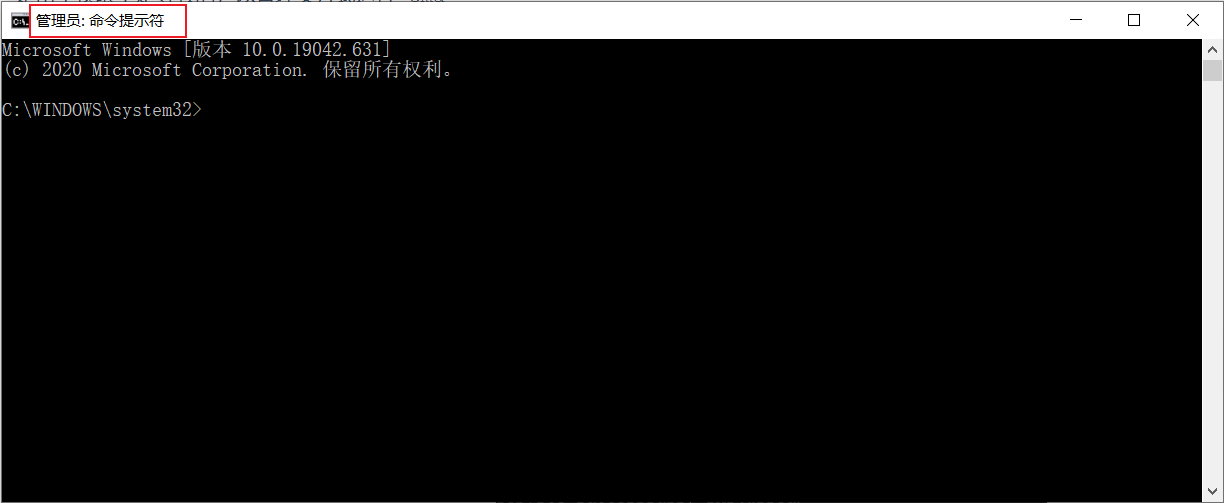

在刚才的命令行中，输入如下的指令： 

````text
mysqld --initialize-insecure
````

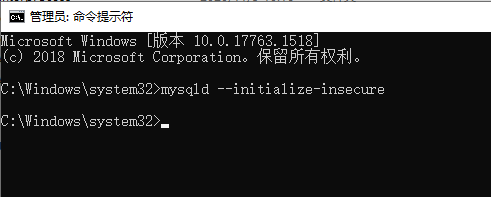

稍微等待一会，如果出现没有出现报错信息，则证明data目录初始化没有问题，此时再查看MySQL目录下已经有data目录生成。

tips：如果出现如下错误

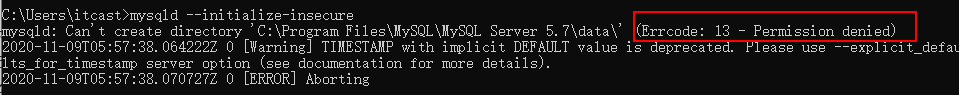

是由于权限不足导致的，以管理员方式运行 cmd

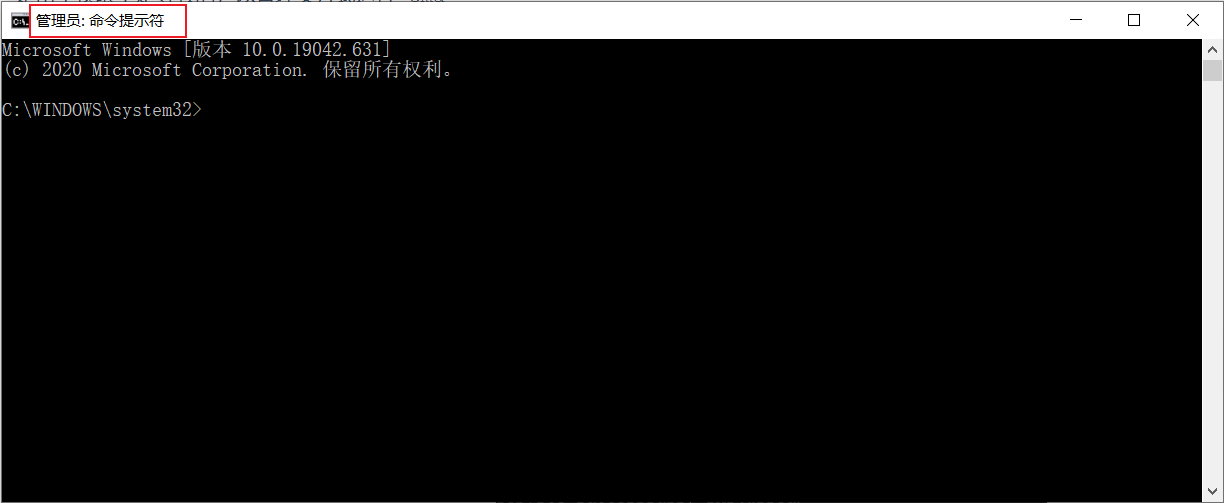


#### 4.2.3 注册MySQL服务

> **补充：**注册 Windows 服务需管理员终端；更明确的形式是 `mysqld --install MySQL`。服务名未必叫 MySQL，实际名称要与后续 net start/net stop 对应。注册服务只是让 Windows 管理其启动，不等于服务已经运行。

命令行（注意必须以管理员身份启动）中，输入如下的指令，回车执行： 

````text
mysqld -install
````

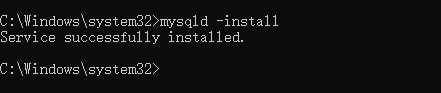

现在你的计算机上已经安装好了MySQL服务了。


#### 4.2.4 启动MySQL服务

> **勘误：**原代码行尾的 `// 启动mysql服务`、`// 停止mysql服务` 不是 CMD 注释，不能整行照抄。实际只执行所需命令：

```text
net start MySQL
```

停止服务时再单独执行 `net stop MySQL`，不应刚启动就把上下两行一起运行。

在黑框里敲入<code>net start mysql</code>，回车。

````text
net start mysql  // 启动mysql服务
    
net stop mysql  // 停止mysql服务
````

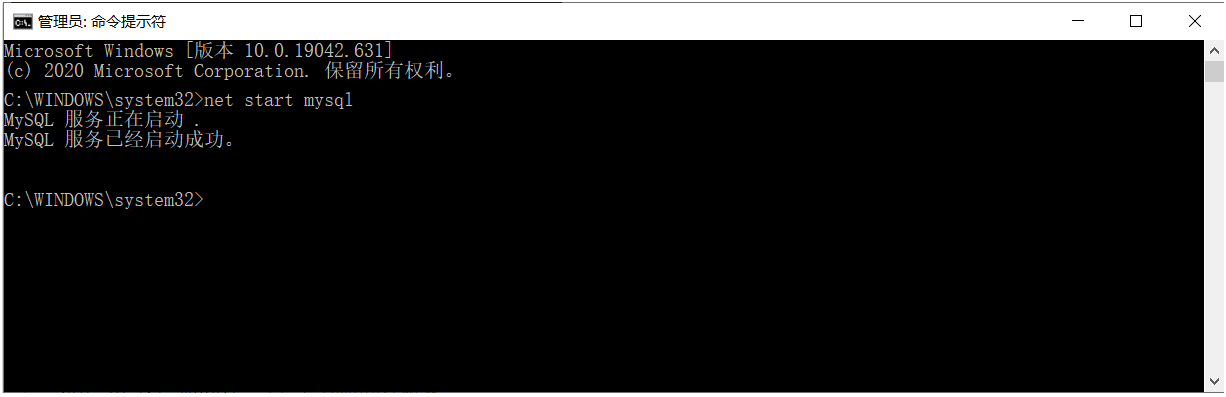


#### 4.2.5 修改默认账户密码

> **补充：**原例的 `1234` 是演示密码。初次空密码登录后，应立即设置自己选择的密码；后续连接可用 `mysql -u root -p`，按提示输入，减少把密码暴露在终端历史记录中。只有原账号仍为空密码时，原文那条不带 `-p` 的 mysqladmin 命令才适用。

在黑框里敲入<code>mysqladmin -u root password 1234</code>，这里的<code>1234</code>就是指默认管理员(即root账户)的密码，可以自行修改成你喜欢的。

````text
mysqladmin -u root password 1234
````

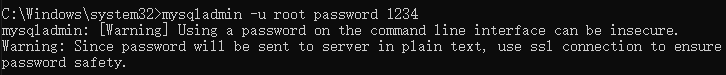


### 4.3 登录

右键开始菜单，选择<code>命令提示符</code>，打开黑框。

在黑框中输入，<code>mysql -uroot -p1234</code>，回车，出现下图且左下角为<code>mysql&gt;</code>，则登录成功。

````text
mysql -uroot -p1234
````

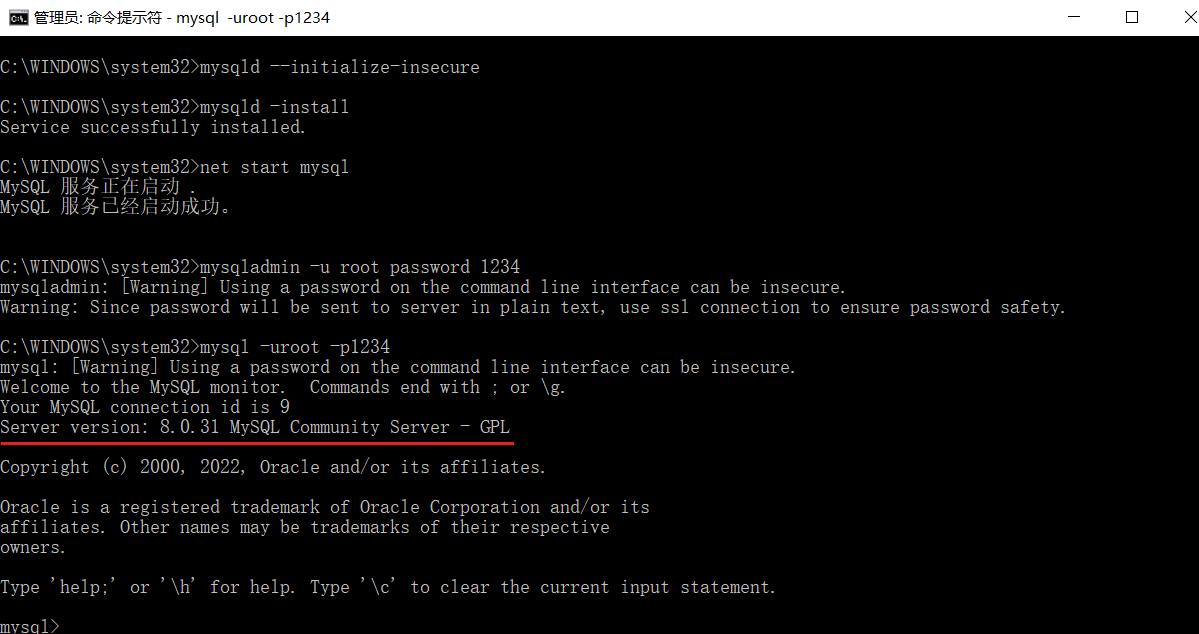

<strong>到这里你就可以开始你的MySQL之旅了！</strong>

退出mysql：

````text
exit
````

登录参数：

````text
mysql -u用户名 -p密码 -h要连接的mysql服务器的ip地址(默认127.0.0.1) -P端口号(默认3306)
````


### 4.4 卸载

> **操作说明：**卸载是可选的环境清理步骤，不是跟练结束后必做。移除服务注册与删除数据目录不是同一件事；需要保留数据库时应先完成备份并确认恢复方式。下文只是讲义操作说明，本次整理笔记没有执行服务安装、停止或删除操作。

如果你想卸载MySQL，也很简单。

点击开始菜单，输入cmd，选择 "命令提示符"，选择右侧的 "以管理员身份运行"。

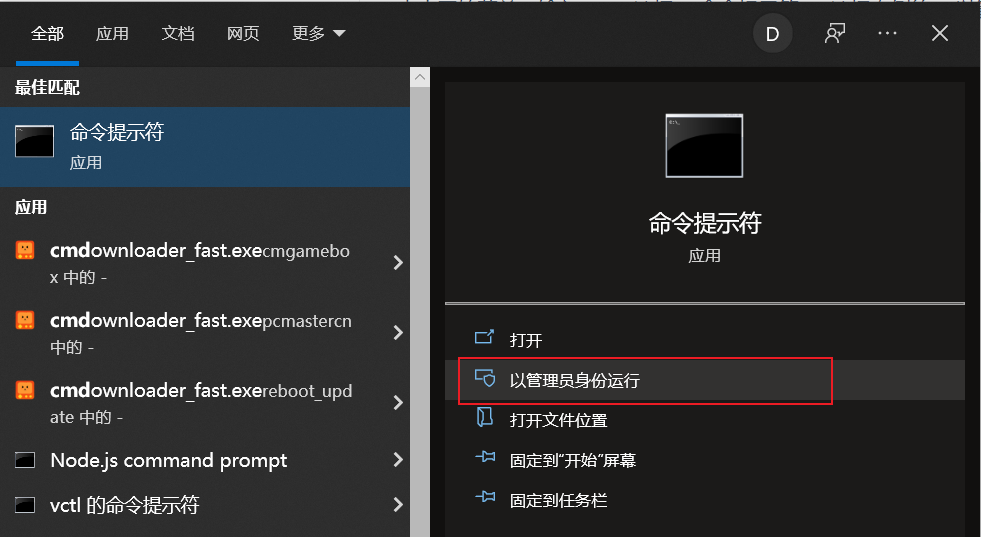

1. 敲入<code>net stop mysql</code>，回车。

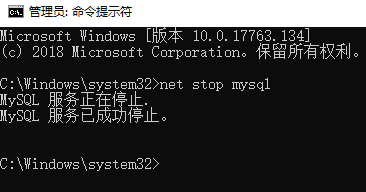

1. 再敲入<code>mysqld -remove mysql</code>，回车。

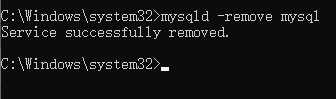

1. 最后删除MySQL目录及相关的环境变量。

<strong>至此，MySQL卸载完成！</strong>


## 5 附录：DataGrip 安装与连接

本节并入课程 [DataGrip 安装文档](https://heuqqdmbyk.feishu.cn/wiki/FAa3wj0nYi4xGBksbFuchBK8nhe) 的安装与连接部分，授权步骤按当前官方文档补充。课程截图的版本、按钮位置可能与当前界面不同；填写的数据库主机、端口、账号应以自己的环境为准。


### 5.1 DataGrip安装


#### 5.1.1 双击 exe 文件安装

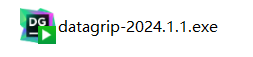


#### 5.1.2 选择安装目录, 下一步

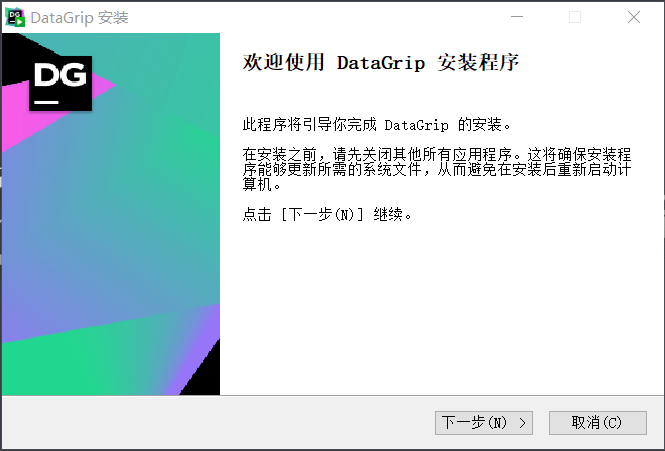

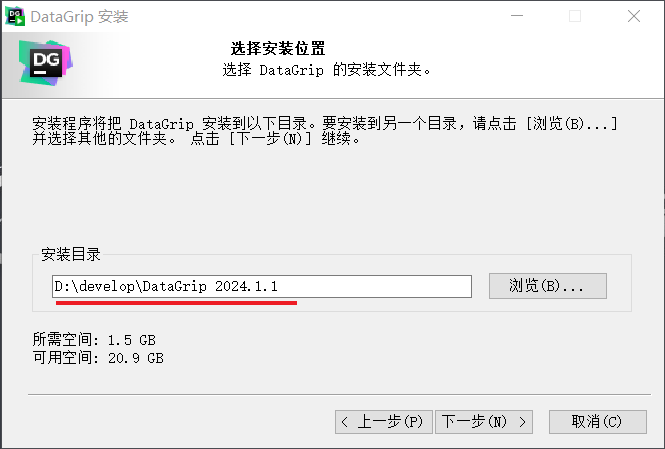


#### 5.1.3 创建快捷方式，安装

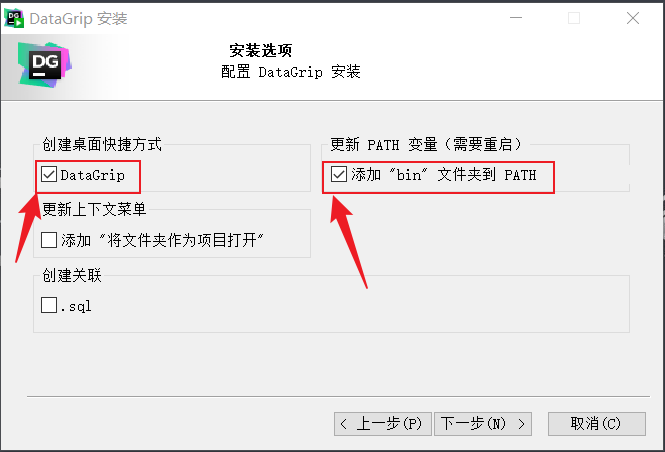

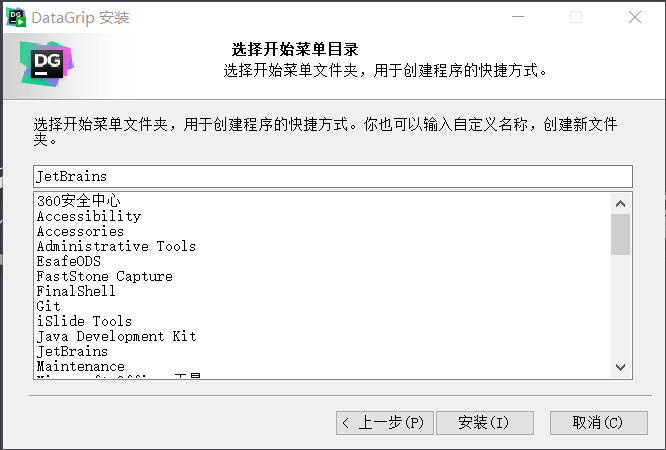

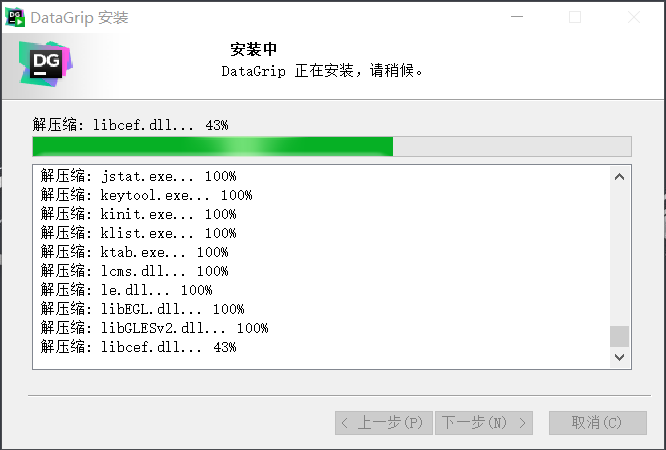


### 5.2 补充：按当前官方方式授权

附属旧文档将非官方补丁/激活流程称为“优化DataGrip”。本笔记以当前官方授权步骤替换这部分，安装和连接数据库的配图仍予保留。

根据 [JetBrains 官方注册说明](https://www.jetbrains.com/help/datagrip/register.html)，DataGrip 2025.2.4 及之后的版本支持符合条件的非商业使用授权。个人学习时可在 **Help → Register → Non-commercial use** 中按提示登录 JetBrains 账号并启用；也可选择官方试用、已有商业许可或符合资格的教育许可。旧版截图没有这一选项时，按当前安装版本的界面操作。

从 [DataGrip 官方下载页](https://www.jetbrains.com/datagrip/download/) 获取安装程序，软件授权完成后再进行下节的数据库连接。DataGrip 授权与 MySQL 数据库账号是两回事。


### 5.3 连接数据库


#### 5.3.1 创建Project

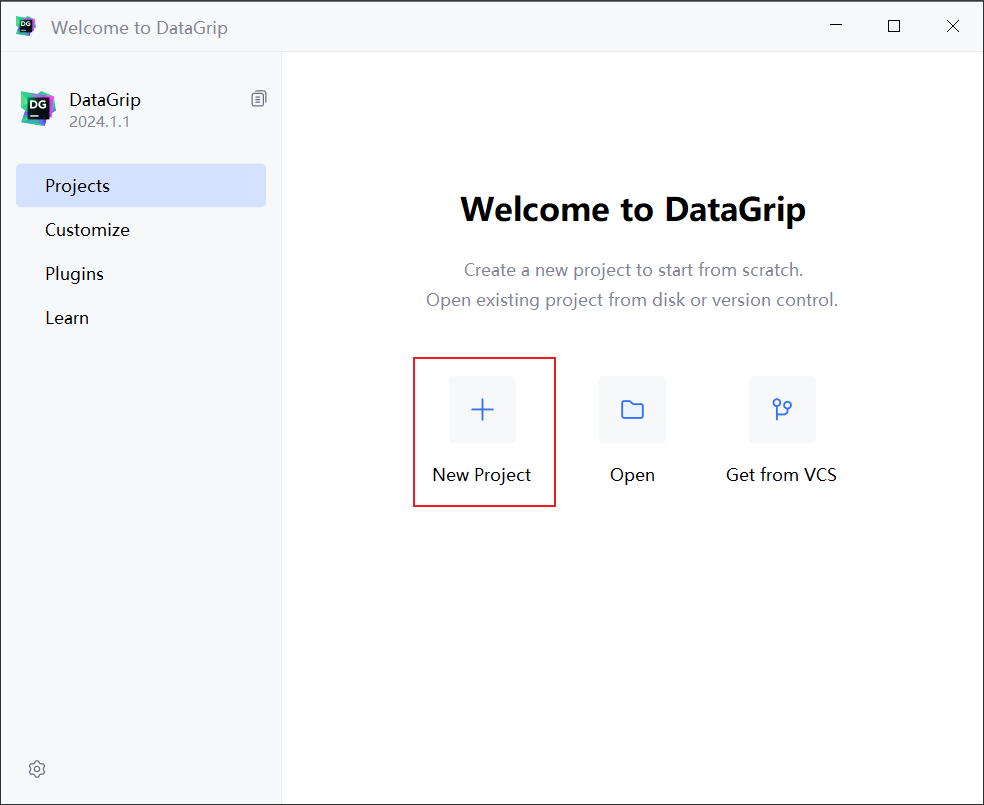

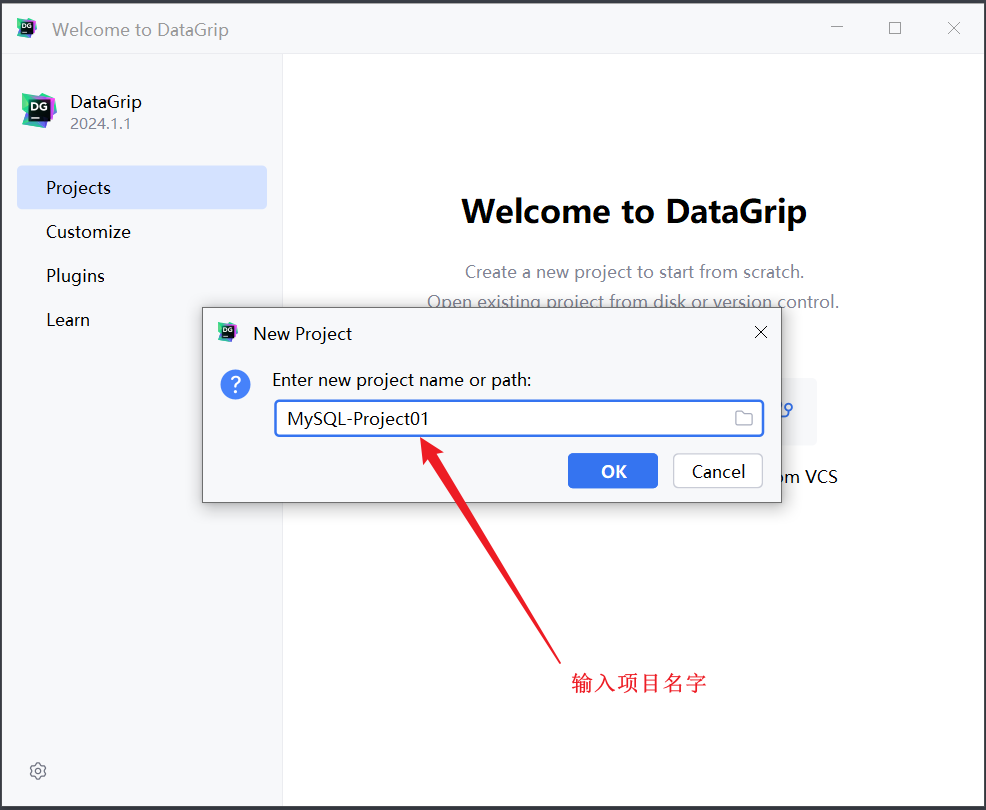


#### 5.3.2 创建连接

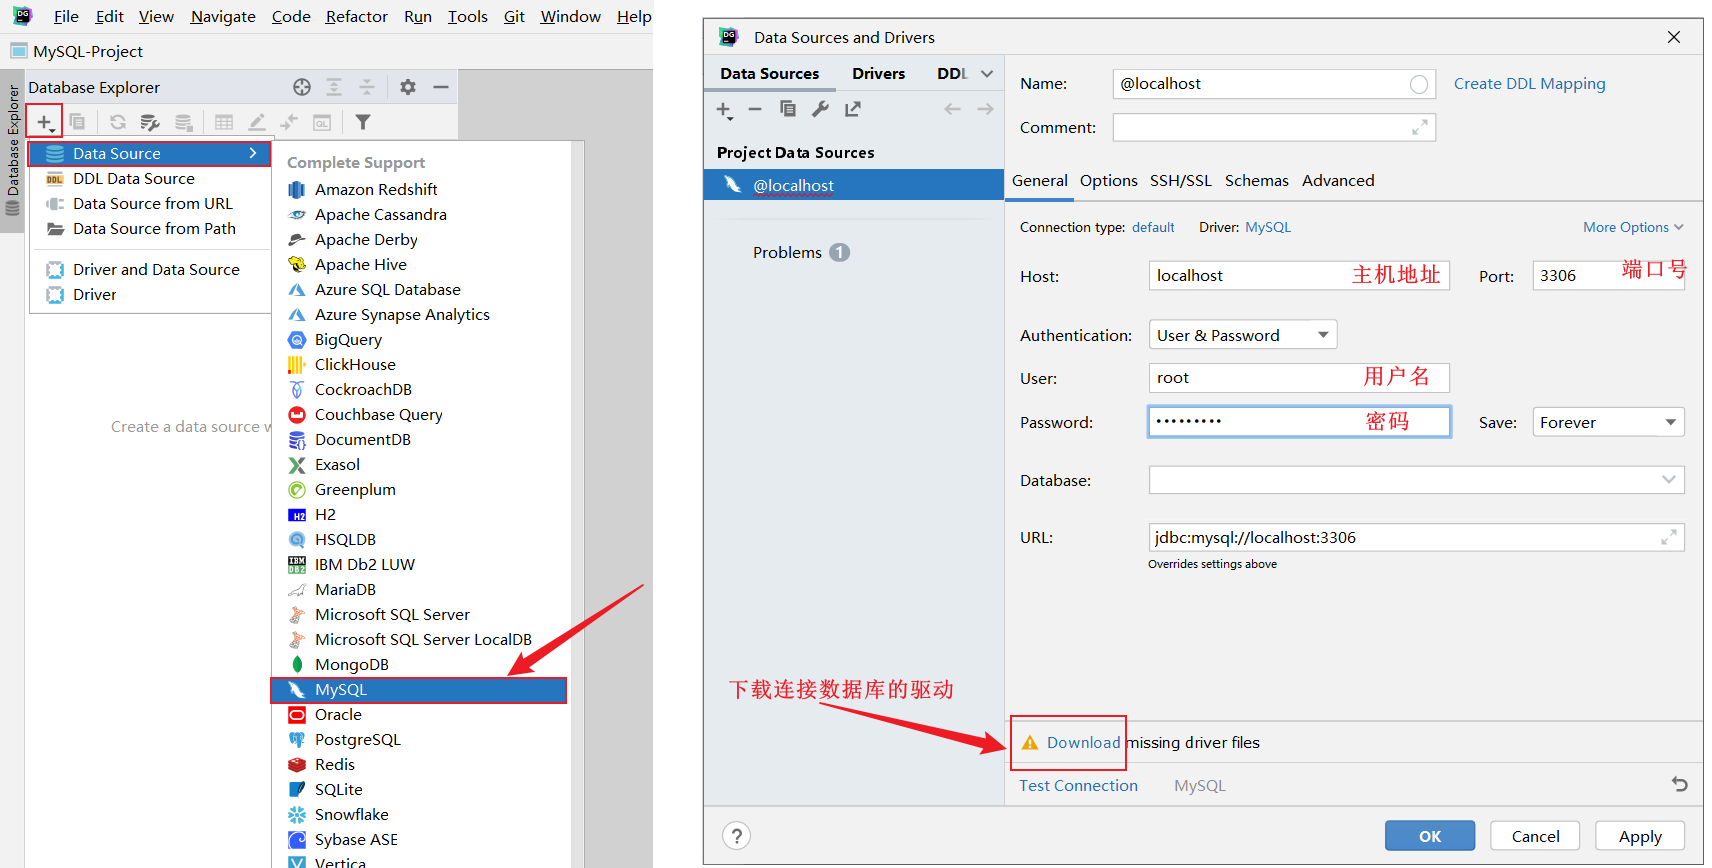

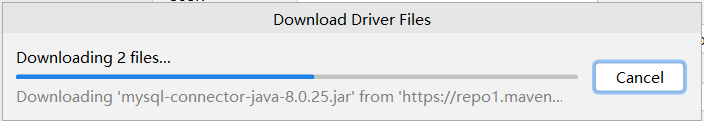

下载驱动, 可能会比较耗时, 耐心等待一会儿。


#### 5.3.3 测试连接

下载完驱动之后，可以点击 Test Connection 来测试一下是否可以正常的连接数据库。

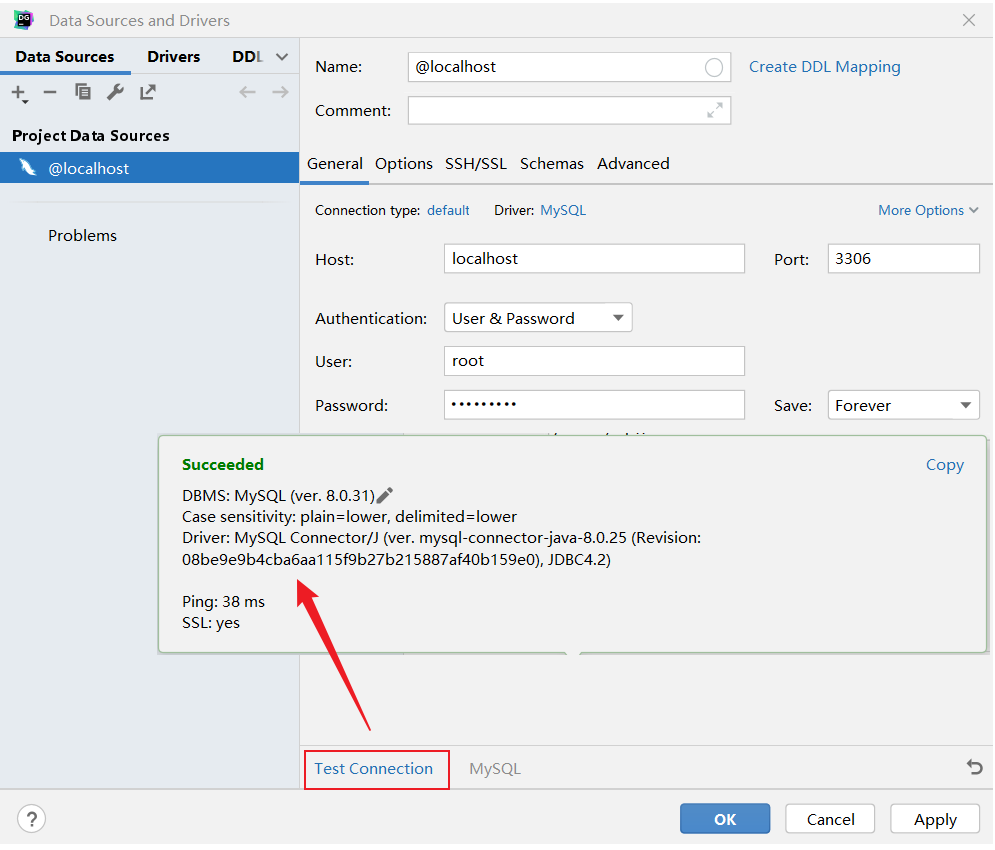

然后点击 OK ， 就已经连接上了MySQL数据库了。


## 6 补充：把 SQL 串成一次完整跟练

本节把容易混淆的准备顺序串起来。使用 MySQL 8.x，在数据库客户端执行代码；先保留一份不变的 30 行查询样本，再在另外的表上练习增删改，后面才能按预期结果核对。


### 6.1 建立查询样本

1. 新建一个专用于本章的练习库，并切换过去：

```sql
CREATE DATABASE javaweb05_practice CHARACTER SET utf8mb4;
USE javaweb05_practice;
SELECT DATABASE();
```

若这个库已经存在，不要直接删除它；先检查是否为自己的旧练习，也可以换一个尚未使用的库名。这里刻意不写自动清空语句。

2. 回到 **3.3.2 语法**，执行其中“准备一些测试数据”下的完整代码块一次：它先创建 `emp`，再插入 30 条样本。这是本章已完整收录的原始初始化代码，不需要另外寻找数据文件。
3. 回到本节确认数据：

```sql
SELECT COUNT(*) AS total,
       COUNT(job) AS assigned_jobs,
       COUNT(salary) AS known_salaries
FROM emp;

SELECT id, name, job, salary FROM emp WHERE id IN (1, 19, 30) ORDER BY id;
```

第一条应为 `30、29、29`；id=1 是施耐庵，id=19 是顾大嫂，id=30 是李云（job、salary 都为 NULL）。若不一致，先检查当前库和是否执行过上一节的 UPDATE/DELETE，不要一边改样本一边对照旧结果。


### 6.2 在独立表练习增删改

`CREATE TABLE ... LIKE` 复制本章 emp 的列定义和索引，不复制数据；它适合在这里准备结构一致的空表。`emp_dml_demo` 也应是尚未存在的练习表名。

```sql
CREATE TABLE emp_dml_demo LIKE emp;

INSERT INTO emp_dml_demo
    (username, password, name, gender, phone, create_time, update_time)
VALUES
    ('wuji', '123456', '张无忌', 1, '13309091231', NOW(), NOW()),
    ('tomone', '123456', '汤姆甲', 1, '13309091232', NOW(), NOW()),
    ('tomtwo', '123456', '汤姆乙', 1, '13309091233', NOW(), NOW());

SELECT COUNT(*) AS total FROM emp_dml_demo; -- 3

-- 先确认更新对象，再执行同条件的更新
SELECT id, username, name FROM emp_dml_demo WHERE username = 'wuji';
UPDATE emp_dml_demo
SET name = '张三', update_time = NOW()
WHERE username = 'wuji';
SELECT username, name FROM emp_dml_demo WHERE username = 'wuji';

-- 再练习只删除一条已确认的记录
SELECT id, username FROM emp_dml_demo WHERE username = 'tomtwo';
DELETE FROM emp_dml_demo WHERE username = 'tomtwo';
SELECT COUNT(*) AS remaining FROM emp_dml_demo; -- 2
```

现在 `emp` 仍有 30 行、`emp_dml_demo` 有 2 行；两个练习互不影响。演示值中的密码仅用于理解 INSERT 的列约束。

**单独体验约束失败：**下面的语句故意重复用户名 `wuji`，应因唯一键冲突而失败；手机号使用新值，以便定位冲突来源。它不是前面成功脚本的一部分。

```sql
INSERT INTO emp_dml_demo(username, password, name, gender, phone)
VALUES ('wuji', '123456', '重复姓名', 1, '13309091299');
```


### 6.3 按正确顺序练习修改表结构

另建空的 `emp_ddl_demo`，保留查询样本和上一节结果。演示列 qq 可空，所以改类型时写清 NULL 和 COMMENT。

```sql
CREATE TABLE emp_ddl_demo LIKE emp;
ALTER TABLE emp_ddl_demo ADD qq VARCHAR(11) NULL COMMENT 'QQ号码';
ALTER TABLE emp_ddl_demo MODIFY qq VARCHAR(13) NULL COMMENT 'QQ号码';
ALTER TABLE emp_ddl_demo CHANGE qq qq_num VARCHAR(13) NULL COMMENT 'QQ号码';
DESC emp_ddl_demo;

ALTER TABLE emp_ddl_demo DROP COLUMN qq_num;
RENAME TABLE emp_ddl_demo TO tb_emp_ddl_demo;
SHOW CREATE TABLE tb_emp_ddl_demo;
```

最后应该看到 `tb_emp_ddl_demo`，且已经没有 qq/qq_num 列。原讲义中的 DROP TABLE、DROP DATABASE 语法已保留在正文，需要清理时先确认具体练习对象；它们不属于本节必须执行的步骤。


### 6.4 查询练习与预期结果

以下均针对未改动的 30 行 `emp`。表内顺序仅在 SQL 显式排序时才有保证。

```sql
-- 1. 查询 NULL，不把它当成 0 或空字符串
SELECT id, name FROM emp WHERE job IS NULL;

-- 2. 范围查询 + AND：分号放在整条语句末尾
SELECT id, name FROM emp
WHERE entry_date BETWEEN '2000-01-01' AND '2010-01-01'
  AND gender = 2;

-- 3. 模糊查询
SELECT id, name FROM emp WHERE name LIKE '%二%' ORDER BY id;

-- 4. 汇总统计
SELECT COUNT(*) AS total, COUNT(salary) AS known_salary,
       MIN(salary) AS min_salary, MAX(salary) AS max_salary,
       SUM(salary) AS total_salary,
       ROUND(AVG(salary), 2) AS average_salary
FROM emp;

-- 5. 先筛选员工，再按职位分组，再筛选汇总结果
SELECT job, COUNT(*) AS employee_count
FROM emp
WHERE entry_date <= '2015-01-01'
GROUP BY job
HAVING COUNT(*) >= 2
ORDER BY job;

-- 6. 固定排序后的第 2 页
SELECT id, name FROM emp ORDER BY id LIMIT 5, 5;
```

| 查询 | 预期结果 |
| --- | --- |
| 1：没有职位 | id=30，李云 |
| 2：日期范围内的女性 | id=19，顾大嫂 |
| 3：名字含“二” | id=15 孙二娘、id=20 阮小二 |
| 4：汇总 | 总人数 30、有薪资 29、最低 4700、最高 15000、总薪资 218900、平均薪资 7548.28 |
| 5：满足条件的职位组 | job=1 有 5 人；job=2 有 11 人；job=5 有 7 人 |
| 6：第 2 页 | id=6～10：扈三娘、柴进、李逵、武松、林冲 |

`ROUND(值, 2)` 表示保留两位小数；平均值的分母是有薪资的 29 人。NULL 薪资并不等于薪资为 0。


## 7 补充：按现象排查

| 现象/报错 | 优先检查 |
| --- | --- |
| `mysql` 不是内部或外部命令 | bin 是否加入 PATH；终端是否重新打开；也可用可执行文件的完整路径 |
| 连接失败 / 2003 / Connection refused | mysqld 是否启动、主机和端口是否正确；先区分服务未启动与账号错误 |
| 1045 / Access denied | 用户名、密码、允许连接的来源主机；不要用“反复初始化”解决登录失败 |
| DataGrip 无法下载驱动 | 客户端驱动下载是独立的网络步骤；不代表 MySQL 安装坏了 |
| 连接成功却看不到库 | Schemas 是否勾选、账号有无权限、是否刷新对象列表 |
| 1046 / No database selected | 在当前连接 `USE 库名`，或写 `库名.表名` |
| 1050 / Table already exists | 是否把迭代版 CREATE TABLE 连续执行，或重复初始化样本 |
| 1146 / Table doesn't exist | 是否混用 emp、emp2、tb_emp，是否执行过 RENAME/DROP，当前库是否正确 |
| 1364 / Field doesn't have a default value | 是否漏传 password 等 NOT NULL 且无默认值的列 |
| 1062 / Duplicate entry | 主键、username、phone 是否重复；核对是否重复执行 INSERT |
| 1064 / SQL syntax error | 是否复制了中文占位词、尾随逗号、提前结束的分号，是否把终端命令当作 SQL |
| 1055 / GROUP BY 不兼容 | SELECT 中的非聚合列是否与分组键匹配，不要通过关闭 SQL 模式掩盖查询含义问题 |
| 查不到 NULL | 是否误写 `= NULL` / `!= NULL`；改用 IS NULL / IS NOT NULL |
| 日期条件结果比预期多/少 | 是否混淆 DATE 与 DATETIME，是否意外执行了无 WHERE 的 UPDATE |
| 分页内容重复、跳动 | 是否有稳定的 ORDER BY、同值时是否补唯一排序键，以及翻页期间数据是否变化 |
| create_time/update_time 没自动填 | DDL 没有默认表达式或自动更新规则时，需要 INSERT/UPDATE 显式维护 |


## 8 本章复习（补充）

| 要能解释的问题 | 回答要点 |
| --- | --- |
| DB、DBMS、客户端有什么区别？ | DB 存表和数据，DBMS 管理数据库，客户端通过连接发送 SQL |
| DDL 与 DML 改什么？ | DDL 改结构；DML 增删改记录；本课程用 DQL 称呼查询 |
| 注释、默认值、约束有什么区别？ | COMMENT 只作说明；DEFAULT 提供省略值时的取值；PRIMARY KEY/UNIQUE/NOT NULL 等限制写入 |
| 主键与唯一约束有何不同？ | 主键唯一且非空，可由多列组合；可空列的 UNIQUE 通常允许多个 NULL |
| NULL、空字符串、0 一样吗？ | 分别表示未知/缺失、长度为 0 的字符串和数值 0，判断及统计行为不同 |
| WHERE 与 HAVING 的区别？ | WHERE 在分组前筛行，HAVING 在分组后筛组；同一查询层的聚合条件通常写在 HAVING |
| COUNT(*) 与 COUNT(salary) 为何不同？ | 前者数所有行，后者只数薪资非 NULL 的行；本章为 30 与 29 |
| 第 p 页、每页 n 条怎样写？ | offset=(p-1)×n，LIMIT offset,n；同时指定可确定次序的 ORDER BY |

**面试提示**：用本章员工表解释 WHERE/HAVING、主键/唯一约束、COUNT 的 NULL 行为，比只背定义更清楚。SQL 的书写顺序与逻辑处理顺序不同；分页中的 offset 是结果行偏移量，不是主键值。

本章把数据存进 MySQL，并通过客户端操作。下一章再学习 Java 怎样连接数据库，把第四章的 Dao 从读取 user.txt 改成访问数据库。


补充核对资料：[MySQL 8.0 数据类型存储要求](https://dev.mysql.com/doc/refman/8.0/en/storage-requirements.html)、[CHAR 与 VARCHAR](https://dev.mysql.com/doc/refman/8.0/en/char.html)、[聚合函数](https://dev.mysql.com/doc/refman/8.0/en/aggregate-functions.html)、[GROUP BY 处理规则](https://dev.mysql.com/doc/refman/8.0/en/group-by-handling.html)、[DataGrip 官方授权说明](https://www.jetbrains.com/help/datagrip/register.html)。
